# Edit fidelity, one turn at a time
### EmbeddingGemma 2 × selective deterministic editing
**A portable visual lab with guarded local multimodal inference.**

A cup changes color, a selected background patch gets a precisely defined contrast edit, and a short sound is inserted and reverted. Three editing trajectories reveal **correct preservation**, **cumulative drift**, and **forgotten history**. We compare MSE, PSNR, valid-window SSIM, exact equality, and genuine EmbeddingGemma 2 representations.

**Start:** select **Restart Kernel and Run All** in JupyterLab. Use the project-local Python **3.12** environments created by `python run_lab.py`. The default `auto` mode attempts real local inference, installs its dependencies in a separate uv-managed environment, and caches results. The first live run needs internet and disk space for dependencies and model weights. No paid API, login prompt, external dataset, CUDA, or FFmpeg is used.

**Evidence boundary:** deterministic experiments run locally; embedding plots appear **only after real model inference or a validated cache**. No CLIP, handcrafted features, random vectors, or caption embeddings are substituted for EmbeddingGemma 2. Offline/unavailable sections are explicitly marked **NOT MEASURED**, and the rest of Run All still completes. The run manifest records the actual platform, device, checkpoint revision, versions, and model coverage.

**Based on:** the supplied *History-Aware Edit Fidelity for n-Dimensional Multimodal Media* survey (November 3, 2026). The fixture, executable checks, and experiments below are a new implementation, not published benchmark results. Model/API references were checked November 4, 2026.

---

## 1 · Run controls
The conservative profile uses **float32**, batch size **one**, **70 image soft tokens**, two-second audio, and **separate short-lived image/text, audio, and video processes**. Available MPS or CUDA is attempted with a bounded CPU fallback; float16, training, and diffusion models are excluded. Truncating output vectors would not reduce model-weight memory, so this lab retains all 768 dimensions.

`auto` reuses a matching local cache before attempting inference. `live` recomputes. `offline` never installs model dependencies or contacts the network. `STRICT_MODEL=True` requires every real embedding; set it to `False` only when an explicitly partial exploration is acceptable.

In [1]:
# These are the only settings needed for a normal run.
MODE = "auto"                    # "auto", "live", or "offline"
AUTO_INSTALL_CORE = True          # installs missing lightweight dependencies with uv
AUTO_INSTALL_MODEL = True         # isolated venv; never upgrades the Jupyter kernel
STRICT_MODEL = True
ENABLE_AUDIO_EMBEDDINGS = True
ENABLE_NATIVE_VIDEO = True        # 8-frame visual-only clip; no joint AV model
DEVICE = "auto"                  # "auto", "cpu", "mps", or "cuda"
MODEL_ID = "google/embeddinggemma-2"
MODEL_REVISION = "main"           # resolved commit is logged; set a SHA for future replication
IMAGE_SOFT_TOKENS = 70            # supported budgets: 70, 140, 280, 560, 1120
CPU_THREADS = 3
WORKER_RSS_LIMIT_GIB = 4.5         # measured process-tree RSS guard, not a hardware guarantee
MIN_FREE_GIB = 0.65               # stops a worker under sustained system memory pressure
SEED = 1729

import os, sys, subprocess, importlib.util, importlib.metadata as metadata
from pathlib import Path
assert MODE in {"auto", "live", "offline"}
assert DEVICE in {"auto", "cpu", "mps", "cuda"}
assert IMAGE_SOFT_TOKENS in {70, 140, 280, 560, 1120}
assert sys.version_info >= (3, 10), "Use Python 3.12 for the supported uv workflow."
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("OMP_NUM_THREADS", str(CPU_THREADS))
os.environ.setdefault("MKL_NUM_THREADS", str(CPU_THREADS))
os.environ.setdefault("OPENBLAS_NUM_THREADS", str(CPU_THREADS))
core = {
    "numpy": "numpy>=1.26,<3", "pandas": "pandas>=2.1,<3",
    "matplotlib": "matplotlib>=3.8,<4", "PIL": "Pillow>=10,<13",
    "scipy": "scipy>=1.11,<2", "skimage": "scikit-image>=0.22,<0.27",
    "psutil": "psutil>=5.9,<8",
}
# Dependencies used by the runner to install Jupyter and execute this notebook.
NOTEBOOK_REQUIREMENTS = [
    "ipykernel>=6.29,<8", "nbclient>=0.10,<1", "nbconvert>=7.16,<8",
    "nbformat>=5.10,<6", "jupyterlab>=4.3,<5", "Jinja2>=3.1,<4",
]
missing = [spec for name, spec in core.items() if importlib.util.find_spec(name) is None]
if missing:
    if not AUTO_INSTALL_CORE:
        raise RuntimeError("Missing packages: " + ", ".join(missing))
    import shutil
    uv = os.environ.get("EDIT_LAB_UV") or shutil.which("uv")
    if not uv:
        raise RuntimeError("uv is required to install notebook dependencies; run python run_lab.py first.")
    subprocess.run([uv, "pip", "install", "--python", sys.executable, *missing], check=True)

import base64, io, json, math, time, hashlib, platform, textwrap, warnings, gc, socket
from dataclasses import dataclass, replace
from enum import Enum
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter
from scipy.ndimage import binary_erosion
from scipy.stats import pearsonr, spearmanr
from skimage.metrics import structural_similarity
import psutil
from IPython.display import display, HTML, Markdown, Audio, FileLink

ROOT = Path.cwd() / "edit_fidelity_outputs"
ASSETS = ROOT / "assets"
FIGURES = ROOT / "figures"
for folder in (ROOT, ASSETS, FIGURES, ROOT / "cache"):
    folder.mkdir(parents=True, exist_ok=True)
RUN_STARTED = time.perf_counter()
CHECKS = []
def check(name, condition):
    assert bool(condition), name
    CHECKS.append(name)

def note(title, text):
    import html
    display(HTML(f'<div class="lab-note"><strong>{html.escape(title)}</strong><br>{html.escape(text)}</div>'))

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.svg", bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.png", dpi=145, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def table(frame, formats=None):
    sty = frame.style.hide(axis="index")
    if formats: sty = sty.format(formats, na_rep="not applicable")
    display(sty)

# Neutral layout styling only; charts use Matplotlib's default color cycle.
display(HTML("""<style>
.lab-note {border:1px solid #cbd5e1;border-left:4px solid #64748b;padding:12px 16px;
 margin:12px 0;border-radius:6px;max-width:920px;line-height:1.55}
.lab-strip {display:flex;gap:16px;flex-wrap:wrap;max-width:960px;margin:14px 0}
.lab-card {flex:1;min-width:210px;max-width:310px;border:1px solid #cbd5e1;
 border-radius:10px;padding:12px;line-height:1.45}
.lab-card img {width:100%;image-rendering:auto;border-radius:5px}
.lab-small {font-size:13px;opacity:.8;margin-top:7px}
.lab-flow {display:flex;align-items:stretch;gap:10px;flex-wrap:wrap;max-width:940px}
.lab-node {flex:1;min-width:170px;border:1px solid #cbd5e1;border-radius:8px;padding:13px}
</style>"""))
if platform.system()=='Darwin' and platform.machine()!='arm64':
    note('Apple Silicon check', 'This Python appears to run under Rosetta. A native arm64 Python environment is recommended.')
note("Runtime", f"{platform.system()} / {platform.machine()} · Python {platform.python_version()} · "
     f"{psutil.virtual_memory().total/2**30:.1f} GiB physical RAM · mode={MODE}")

In [2]:
display(HTML("""<div class="lab-flow">
<div class="lab-node"><b>1. Specify</b><br>Property, scope, target,<br>reference revision.</div>
<div class="lab-node"><b>2. Edit exactly</b><br>Change authorized samples.<br>Copy everything else.</div>
<div class="lab-node"><b>3. Measure</b><br>Pixels + waveform +<br>learned representations.</div>
<div class="lab-node"><b>4. Check history</b><br>Persist, override, revert.<br>Never silently forget.</div>
</div>"""))

## 2 · A small, fully reproducible media asset
The image is a 256 × 192 RGB illustration, constructed from fixed arrays and masks. The audio is a two-second, 16 kHz float32 signal. There are no downloaded photographs or font dependencies.

A hard compositor uses boolean indexing, not a global re-render:
\[
Y[p]=\begin{cases}E[p],&p\in M,\\X[p],&p\notin M.\end{cases}
\]
The contrast operator is explicitly **channelwise encoded-sRGB contrast around 127.5**, with factor **1.237**, clipping to [0,255], and round-to-nearest/ties-to-even. It is **not** linear-light contrast or an arbitrary application slider. Audio editing also assigns only the declared half-open sample interval.


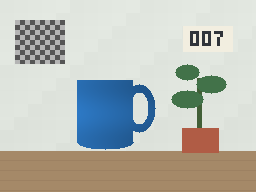

In [3]:
H, W, SR = 192, 256, 16_000
DURATION = 2.0
YY, XX = np.mgrid[:H, :W]
CUP_COLORS = {"blue": (42, 113, 184), "red": (192, 64, 65), "green": (49, 142, 91)}
BODY = (XX >= 77) & (XX < 133) & (YY >= 80) & (YY < 143)
BODY |= ((XX-105)/28)**2 + ((YY-142)/7)**2 <= 1
HANDLE = ((((XX-139)/16)**2 + ((YY-108)/24)**2 <= 1) &
          (((XX-139)/9)**2 + ((YY-108)/16)**2 >= 1) & (XX >= 130))
CUP = BODY | HANDLE
PATCH = (XX >= 15) & (XX < 65) & (YY >= 20) & (YY < 64)
STATIC = ~(CUP | PATCH)
LOGO = (XX >= 183) & (XX < 233) & (YY >= 26) & (YY < 52)
DRIFT_MASK = STATIC & (YY < 65) & ~LOGO
AUDIO_INTERVAL = (int(1.0*SR), int(1.18*SR))

# A fixed 3x5 raster alphabet avoids OS-dependent font rendering.
DIGITS = {
 '0': ['111','101','101','101','111'], '1':['010','110','010','010','111'],
 '2': ['111','001','111','100','111'], '3':['111','001','111','001','111'],
 '4': ['101','101','111','001','001'], '5':['111','100','111','001','111'],
 '6': ['111','100','111','101','111'], '7':['111','001','010','010','010'],
 '8': ['111','101','111','101','111'], '9':['111','101','111','001','111'],
}
def write_code(img, text):
    result = img.copy()
    result[LOGO] = (242, 238, 224)
    for k, ch in enumerate(text):
        for row, line in enumerate(DIGITS[ch]):
            for col, bit in enumerate(line):
                if bit == '1':
                    y, x = 31+3*row, 190+12*k+3*col
                    result[y:y+3, x:x+3] = (48, 52, 58)
    return result

def recolor(img, rgb):
    result = img.copy()
    # Fixed spatial shading; assigning the same color is idempotent.
    shade = np.clip(0.83 + 0.19*(133-XX)/56 + 0.05*np.cos(YY/9), 0.76, 1.07)
    fill = np.rint(np.clip(shade[...,None]*np.array(rgb), 0, 255)).astype(np.uint8)
    result[CUP] = fill[CUP]
    return result

def scene():
    img = np.empty((H,W,3), dtype=np.uint8)
    for c, val in enumerate((224, 229, 222)):
        img[...,c] = (val + (XX//14+YY//13)%5 - YY//30).astype(np.uint8)
    img[YY >= 151] = (165, 137, 104)
    img[(YY >= 151) & ((YY%10)==0)] = (157, 129, 98)
    # Selected background patch has sufficient texture for contrast/SSIM.
    checker = ((XX//5 + YY//5)%2)[...,None]
    patch_pixels = np.broadcast_to(85 + checker*95, (H,W,3)).astype(np.uint8)
    img[PATCH] = patch_pixels[PATCH]
    # A protected plant and its pot.
    img[(XX >= 197)&(XX < 202)&(YY >= 78)&(YY < 144)] = (65, 95, 55)
    for cx,cy,rx,ry in [(187,99,16,9),(211,84,15,9),(187,72,12,8)]:
        img[((XX-cx)/rx)**2+((YY-cy)/ry)**2 <= 1] = (66, 114, 73)
    img[(XX >= 182)&(XX < 219)&(YY >= 128)&(YY < 153)] = (176, 92, 69)
    img = write_code(img, '007')
    return recolor(img, CUP_COLORS['blue'])

IMAGE0 = scene()
T = np.arange(int(SR*DURATION), dtype=np.float64)/SR
AUDIO0 = (0.035*np.sin(2*np.pi*220*T)).astype(np.float32)
start, stop = AUDIO_INTERVAL
u = np.arange(stop-start)/SR
BELL = (0.23*np.sin(2*np.pi*880*u)*np.exp(-20*u)).astype(np.float32)

@dataclass
class Media:
    image: np.ndarray
    audio: np.ndarray
    def copy(self): return Media(self.image.copy(), self.audio.copy())

BASE = Media(IMAGE0, AUDIO0)
def image_uri(image):
    buf=io.BytesIO(); Image.fromarray(image).save(buf,format='PNG')
    return 'data:image/png;base64,'+base64.b64encode(buf.getvalue()).decode()

def cards(items):
    import html
    parts=[]
    for title, image, caption in items:
        parts.append(f'<div class="lab-card"><b>{html.escape(title)}</b><br>'
                     f'<img src="{image_uri(image)}"><div class="lab-small">{html.escape(caption)}</div></div>')
    display(HTML('<div class="lab-strip">'+''.join(parts)+'</div>'))

cards([('Source • turn 0', IMAGE0, 'Blue cup; code 007; protected plant; a small textured edit region.')])
check('masks are disjoint', not np.any(CUP & PATCH))
check('audio has declared shape', AUDIO0.shape == (32000,))
check('source pixel dtype', IMAGE0.dtype == np.uint8)

## 3 · Six turns, with explicit overrides and reversions
| Turn | New instruction | What remains active |
|:--|:--|:--|
| 1 | Make the cup red. | Original patch and audio. |
| 2 | Set the selected patch contrast to 1.237. | Red cup; original audio. |
| 3 | Add the bell only in [1.00, 1.18) s. | Red cup; edited patch. |
| 4 | Make the cup green **instead**. | Edited patch; bell. Red is superseded. |
| 5 | Restore the **original audio**. | Green cup; edited patch. Bell is reverted. |
| 6 | Restore the **original patch**. | Green cup; original audio. |

The ledger is compiled from **structured edit operations** below, not from an unvalidated LLM. The English instructions are labels. All reference targets are built from the clean specification, never from a corrupted rollout.


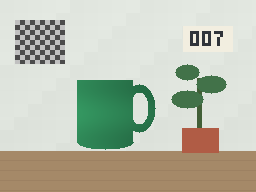
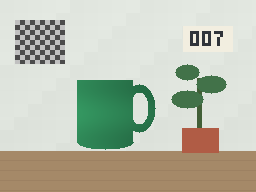
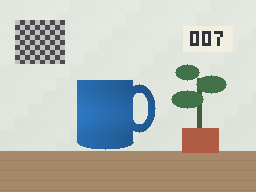

In [4]:
INSTRUCTIONS = [
 'Source', 'Cup → red', 'Patch contrast × 1.237', 'Insert local bell',
 'Cup → green (override)', 'Original audio (revert)', 'Original patch (revert)',
]
PROPERTIES = ['cup', 'patch', 'audio', 'static']
UPDATE_PROPERTY = {1:'cup', 2:'patch', 3:'audio', 4:'cup', 5:'audio', 6:'patch'}

def edit(previous, turn):
    out = previous.copy()
    if turn in (1,4):
        color = 'red' if turn==1 else 'green'
        out.image = recolor(previous.image, CUP_COLORS[color])
    elif turn==2:
        target = np.rint(np.clip(127.5 + 1.237*(IMAGE0.astype(np.float64)-127.5),0,255)).astype(np.uint8)
        out.image[PATCH] = target[PATCH]
    elif turn==3:
        out.audio[start:stop] = AUDIO0[start:stop] + BELL
    elif turn==5:
        out.audio[:] = AUDIO0
    elif turn==6:
        out.image[PATCH] = IMAGE0[PATCH]
    else:
        raise ValueError(f'Unknown editing turn {turn}')
    return out

# Authoritative targets and versioned obligations.
TARGETS=[BASE.copy()]
for k in range(1,7): TARGETS.append(edit(TARGETS[-1],k))
@dataclass(frozen=True)
class Obligation:
    identifier: str
    property: str
    born: int
    until: int
    reference_turn: int
    label: str

LEDGER = [
 Obligation('cup.blue.v0','cup',0,1,0,'blue'),
 Obligation('cup.red.v1','cup',1,4,1,'red'),
 Obligation('cup.green.v2','cup',4,7,4,'green'),
 Obligation('patch.original.v0','patch',0,2,0,'original'),
 Obligation('patch.contrast.v1','patch',2,6,2,'×1.237'),
 Obligation('patch.original.v2','patch',6,7,0,'original'),
 Obligation('audio.original.v0','audio',0,3,0,'original'),
 Obligation('audio.bell.v1','audio',3,5,3,'bell'),
 Obligation('audio.original.v2','audio',5,7,0,'original'),
 Obligation('static.original.v0','static',0,7,0,'protected'),
]
def active(turn): return [c for c in LEDGER if c.born <= turn < c.until]
def pixels(media, prop):
    if prop=='audio': return media.audio
    return media.image[{'cup':CUP,'patch':PATCH,'static':STATIC}[prop]]
def satisfied(media, c):
    return np.array_equal(pixels(media,c.property), pixels(TARGETS[c.reference_turn],c.property))

def rollout(policy):
    trace=[BASE.copy()]
    for k in range(1,7):
        out=edit(trace[-1],k)
        if policy=='drift':
            # Deterministic, unauthorized +1 code-value shift every turn.
            out.image[DRIFT_MASK]=np.clip(out.image[DRIFT_MASK].astype(np.int16)+1,0,255).astype(np.uint8)
        elif policy=='forget' and k==5:
            # Reverting audio accidentally restores the OLD cup as well.
            out.image[CUP]=IMAGE0[CUP]
        elif policy=='no-op':
            out=trace[-1].copy()
        trace.append(out)
    return trace
TRACES={p:rollout(p) for p in ('exact','drift','forget','no-op')}
POLICY_LABEL={'exact':'Exact selective', 'drift':'Background drift', 'forget':'Forgot green', 'no-op':'No-op'}
check('exact trajectory matches every target', all(np.array_equal(a.image,b.image) and np.array_equal(a.audio,b.audio)
      for a,b in zip(TRACES['exact'],TARGETS)))
check('red is superseded at turn 4', not any(c.identifier=='cup.red.v1' for c in active(4)))
check('audio reversion preserves green', satisfied(TARGETS[5],next(c for c in active(5) if c.property=='cup')))

cards([
 ('Turn 4 • green is active', TARGETS[4].image, 'The next instruction changes audio only.'),
 ('Turn 5 • correct reversion', TRACES['exact'][5].image, 'Audio returns to the original. The green cup remains.'),
 ('Turn 5 • forgotten history', TRACES['forget'][5].image, 'Audio is correct, but the old blue cup returns.'),
])

### Obligations are a timeline, not a bag of old prompts
A requirement is evaluated only while its version is active. The marked regression is an actual measured failure of the green-cup requirement in the `forget` trajectory. Restoring the original soundtrack is **not** a failure to retain the bell: that requirement was explicitly retired.

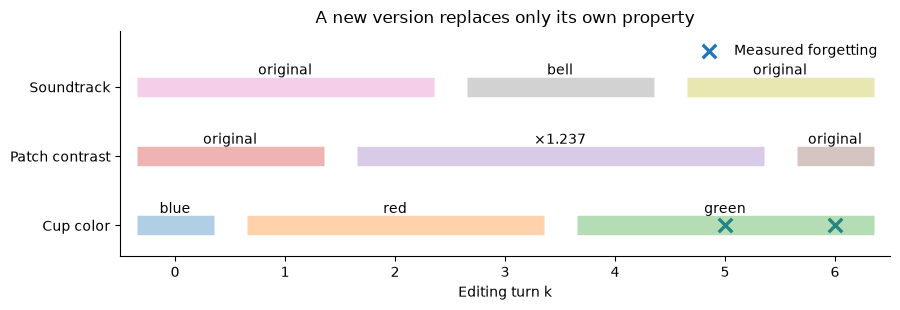

In [5]:
fig,ax=plt.subplots(figsize=(9.1,3.2))
for yi, prop in enumerate(['cup','patch','audio']):
    for c in [c for c in LEDGER if c.property==prop]:
        left,right=c.born-0.35,c.until-0.65
        ax.plot([left,right],[yi,yi],linewidth=14,solid_capstyle='butt',alpha=.35)
        ax.text((left+right)/2,yi+.13,c.label,ha='center',va='bottom',fontsize=10)
ax.scatter([5,6],[0,0],marker='x',s=95,linewidths=2.4,label='Measured forgetting')
ax.set(yticks=[0,1,2],yticklabels=['Cup color','Patch contrast','Soundtrack'],xticks=range(7),
       xlim=(-.5,6.5),ylim=(-.45,2.8),xlabel='Editing turn k',title='A new version replaces only its own property')
ax.legend(loc='upper right',frameon=False)
ax.spines[['top','right']].set_visible(False)
finish(fig,'01_requirement_lifetimes')

## 4 · Measure the right support against the right reference
Image MSE uses RGB samples normalized to [0,1]. PSNR uses a fixed peak of 1:
\[
\operatorname{PSNR}=-10\log_{10}(\operatorname{MSE}),\qquad
\operatorname{MSE}=0\Rightarrow\operatorname{PSNR}=+\infty.
\]
The exactness check also reports maximum code-value error and the fraction of changed **pixels** (any RGB channel changed). No uint8 subtraction is used.

SSIM uses the documented scikit-image implementation with a **7 × 7 uniform window**, `data_range=1`, and channel averaging. Protected SSIM averages only windows entirely inside the protected region, obtained by 7 × 7 binary erosion; it never blackens everything outside a mask. Its valid support is therefore smaller than the MSE support. This is an explicit configuration, not the original paper's Gaussian-window variant. [Metric API](https://scikit-image.org/docs/0.26.x/api/skimage.metrics.html).

In [6]:
def image_metrics(reference, candidate, mask=None):
    if reference.shape != candidate.shape: raise ValueError('Corresponding shapes required')
    if mask is None: mask=np.ones(reference.shape[:2],dtype=bool)
    if mask.dtype!=bool or mask.shape!=reference.shape[:2]: raise ValueError('Invalid support')
    if not mask.any(): raise ValueError('Empty evaluation support')
    a=reference.astype(np.float64)/255.0; b=candidate.astype(np.float64)/255.0
    delta=a-b
    mse=float(np.mean(np.square(delta[mask])))
    raw=reference.astype(np.int16)-candidate.astype(np.int16)
    exact=bool(np.array_equal(reference[mask],candidate[mask]))
    # Define equality exactly; do not pretend a numerical SSIM tolerance certifies it.
    _,smap=structural_similarity(a,b,channel_axis=2,data_range=1.0,win_size=7,
                                gaussian_weights=False,use_sample_covariance=True,full=True)
    valid=binary_erosion(mask,structure=np.ones((7,7),dtype=bool),border_value=0)
    valid_ssim=float(np.mean(smap[valid])) if valid.any() else np.nan
    return dict(mse=mse,psnr=np.inf if mse==0 else -10*np.log10(mse),ssim=valid_ssim,
                max_code_error=int(np.max(np.abs(raw[mask]))),
                changed_pixel_rate=float(np.mean(np.any(raw!=0,axis=2)[mask])),exact=exact,
                mse_pixels=int(mask.sum()),ssim_centers=int(valid.sum()))

def transition_preserved(previous, current, turn):
    im_edit=np.zeros((H,W),bool); au_edit=np.zeros(len(AUDIO0),bool)
    if turn in (1,4): im_edit=CUP
    elif turn in (2,6): im_edit=PATCH
    elif turn==3: au_edit[start:stop]=True
    elif turn==5: au_edit[:]=True
    return (np.array_equal(previous.image[~im_edit],current.image[~im_edit]) and
            np.array_equal(previous.audio[~au_edit],current.audio[~au_edit]))

records=[]
for policy,trace in TRACES.items():
    for k,current in enumerate(trace):
        obs=active(k)
        current_req=[c for c in obs if c.born==k] if k else []
        earlier=[c for c in obs if c.born<k]
        source=image_metrics(IMAGE0,current.image)
        goal=image_metrics(TARGETS[k].image,current.image)
        protected=image_metrics(IMAGE0,current.image,STATIC)
        records.append(dict(policy=policy,turn=k,
            I=float(np.mean([satisfied(current,c) for c in current_req])) if current_req else np.nan,
            P=float(transition_preserved(trace[k-1],current,k)) if k else np.nan,
            H=float(np.mean([satisfied(current,c) for c in earlier])) if earlier else np.nan,
            C=np.nan,all_active=all(satisfied(current,c) for c in obs),
            source_mse=source['mse'],source_psnr=source['psnr'],source_ssim=source['ssim'],
            goal_mse=goal['mse'],protected_mse=protected['mse'],protected_ssim=protected['ssim'],
            protected_max=protected['max_code_error'],protected_changed=protected['changed_pixel_rate']))
RESULTS=pd.DataFrame(records)
summary=RESULTS[RESULTS.turn==6].copy()
summary['Trajectory']=summary.policy.map(POLICY_LABEL)
table(summary[['Trajectory','source_mse','source_psnr','source_ssim','goal_mse','protected_max','all_active']],
      {'source_mse':'{:.6f}','source_psnr':'{:.2f}','source_ssim':'{:.4f}','goal_mse':'{:.6f}'})
note('Read the two references separately',
     'Source similarity rewards doing nothing. Goal MSE compares with the known final target in this synthetic fixture. '
     'Real open-ended editing often has no single pixel-aligned target. Exact preservation uses the protected region.')

ident=image_metrics(IMAGE0,IMAGE0)
check('identity MSE zero',ident['mse']==0)
check('identity PSNR infinite',np.isposinf(ident['psnr']))
check('identity SSIM one',np.isclose(ident['ssim'],1))
check('protected mask excludes authorized edits', image_metrics(IMAGE0,TARGETS[4].image,STATIC)['max_code_error']==0)
check('valid SSIM support smaller than MSE support',ident['ssim_centers'] < ident['mse_pixels'])
check('all exact turns preserve protected samples',all(transition_preserved(TARGETS[k-1],TARGETS[k],k) for k in range(1,7)))

Trajectory,source_mse,source_psnr,source_ssim,goal_mse,protected_max,all_active
Exact selective,0.003515,24.54,0.9885,0.000000,0,True
Background drift,0.003663,24.36,0.9845,0.000148,6,False
Forgot green,0.000000,inf,1.0000,0.003515,0,False
No-op,0.000000,inf,1.0000,0.003515,0,False


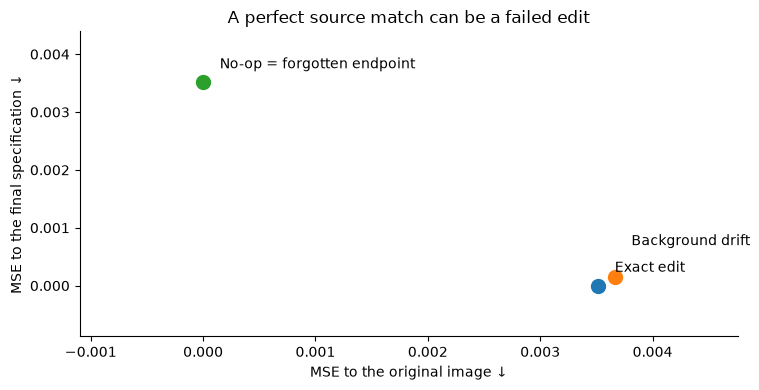

In [7]:
fig,ax=plt.subplots(figsize=(7.8,4.0))
# Forgotten and no-op endpoints are identical; label the common point once.
for p,label,offset in [('exact','Exact edit',(12,10)),('drift','Background drift',(12,23)),
                       ('no-op','No-op = forgotten endpoint',(12,10))]:
    r=summary[summary.policy==p].iloc[0]
    ax.scatter(r.source_mse,r.goal_mse,s=100)
    ax.annotate(label,(r.source_mse,r.goal_mse),xytext=offset,textcoords='offset points',fontsize=10)
ax.margins(x=.30,y=.25)
ax.set(xlabel='MSE to the original image ↓',ylabel='MSE to the final specification ↓',
       title='A perfect source match can be a failed edit')
ax.spines[['top','right']].set_visible(False)
finish(fig,'02_source_is_not_goal')

### Slow drift hides in small turn-to-turn differences
The drift policy adds one code value to a protected background region on every turn. Both measurements below use the **same fixed region**. A small immediate error does not imply small error to the property's original anchor.

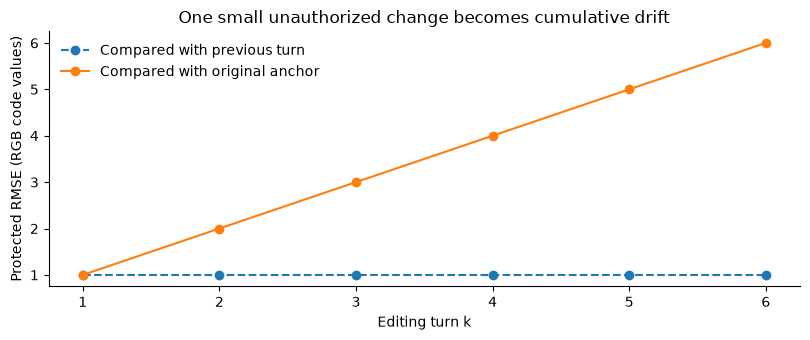

In [8]:
step=[]; anchor=[]
for k in range(1,7):
    trace=TRACES['drift']
    step.append(np.sqrt(image_metrics(trace[k-1].image,trace[k].image,DRIFT_MASK)['mse'])*255)
    anchor.append(np.sqrt(image_metrics(IMAGE0,trace[k].image,DRIFT_MASK)['mse'])*255)
fig,ax=plt.subplots(figsize=(8.2,3.5))
ax.plot(range(1,7),step,'o--',label='Compared with previous turn')
ax.plot(range(1,7),anchor,'o-',label='Compared with original anchor')
ax.set(xticks=range(1,7),xlabel='Editing turn k',ylabel='Protected RMSE (RGB code values)',
       title='One small unauthorized change becomes cumulative drift')
ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False)
finish(fig,'03_cumulative_drift')
check('one code value of immediate drift',np.allclose(step,1))
check('anchor drift grows by one per turn',np.allclose(anchor,np.arange(1,7)))

## 5 · Multi-turn is not repeated single-turn
An **oracle-input** test starts every turn from the approved preceding state. A **self-fed rollout** starts from the editor's own output. A **consolidated** edit starts from the original and executes the final surviving specification: *green cup; original patch; original audio*.

Our deterministic operators are deliberately simple enough that the clean rollout and consolidated result are identical. This is a property tested for this fixture, **not** a general claim that arbitrary semantic edits commute or collapse into one turn. The final `forget` image equals the no-op image, yet their histories are different.

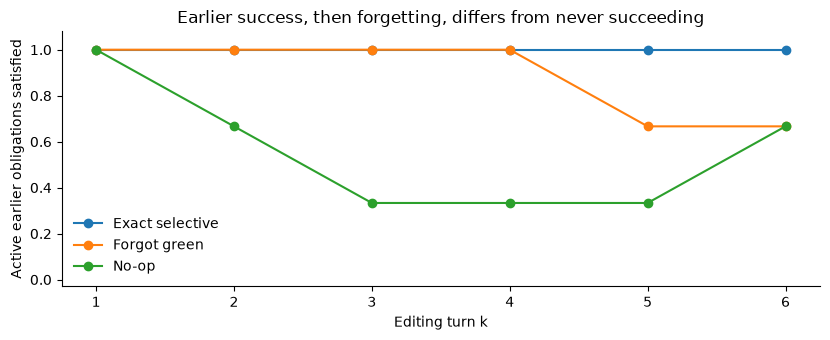

In [9]:
ORACLE=[BASE.copy()]+[edit(TARGETS[k-1],k) for k in range(1,7)]
CONSOLIDATED=BASE.copy()
CONSOLIDATED.image=recolor(IMAGE0,CUP_COLORS['green'])
check('oracle turns match targets',all(np.array_equal(ORACLE[k].image,TARGETS[k].image) and
      np.array_equal(ORACLE[k].audio,TARGETS[k].audio) for k in range(7)))
check('consolidated image matches clean rollout',np.array_equal(CONSOLIDATED.image,TARGETS[6].image))
check('consolidated audio matches clean rollout',np.array_equal(CONSOLIDATED.audio,TARGETS[6].audio))
check('same endpoint does not imply same history',
      np.array_equal(TRACES['forget'][6].image,TRACES['no-op'][6].image) and
      not np.array_equal(TRACES['forget'][4].image,TRACES['no-op'][4].image))

fig,ax=plt.subplots(figsize=(8.4,3.5))
for p in ('exact','forget','no-op'):
    g=RESULTS[(RESULTS.policy==p)&(RESULTS.turn>0)]
    ax.plot(g.turn,g.H,marker='o',label=POLICY_LABEL[p])
ax.set(xticks=range(1,7),ylim=(-.03,1.08),xlabel='Editing turn k',ylabel='Active earlier obligations satisfied',
       title='Earlier success, then forgetting, differs from never succeeding')
ax.legend(frameon=False,loc='lower left'); ax.spines[['top','right']].set_visible(False)
finish(fig,'04_history_retention')
note('Four dimensions, not one blended score',
     'I: current instruction; P: immediate protected-sample preservation; H: active earlier obligations; '
     'C: prescribed relations. C is not applicable in this uncoupled image/audio story. The next experiment adds an explicit relation.')

## 6 · Audio and video: editing turn k is not media time τ
The inserted bell occupies only [1.00,1.18) seconds. Original samples outside that interval are copied exactly. Playback uses `normalize=False`, so the player does not erase amplitude differences through per-clip normalization.

The small additional audio-video example has a flash at 1.00 s. A separate relation requires the beep onset to agree within 0.10 s. Delaying audio by 0.25 s violates that relation even though every video frame is identical. Image PSNR cannot evaluate audio timing; waveform MSE cannot evaluate a visual relationship. We do **not** apply image SSIM to raw audio.

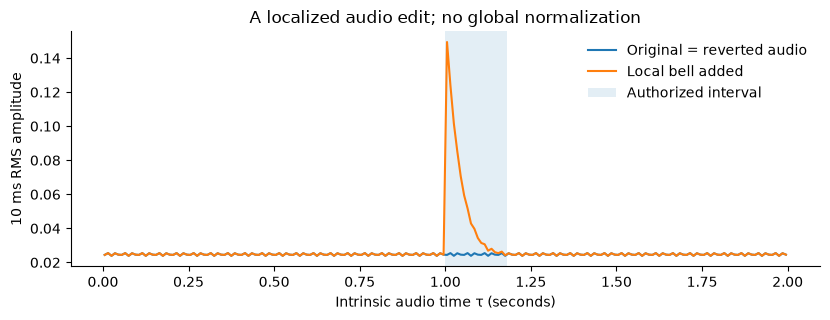

Turn 3: local bell


Turn 5: original audio restored


pair,offset_ms,relation_pass
Same video + aligned audio,0.063,True
Same video + delayed audio,250.063,False



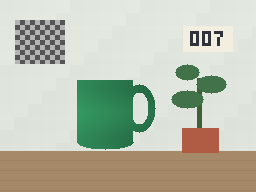

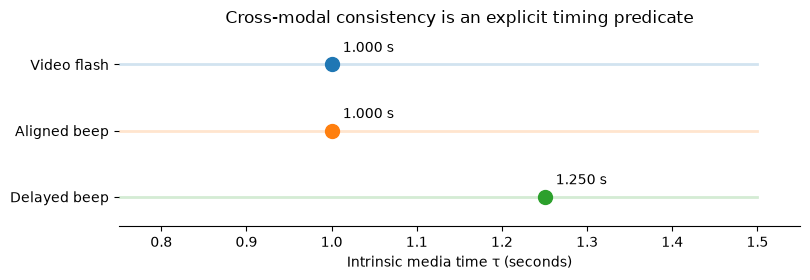

In [10]:
# Compact envelope rather than a dense waveform plot.
block=160
rms=lambda a:np.sqrt(np.mean(a.reshape(-1,block).astype(np.float64)**2,axis=1))
centers=(np.arange(len(AUDIO0)//block)+.5)*block/SR
fig,ax=plt.subplots(figsize=(8.4,3.3))
ax.plot(centers,rms(AUDIO0),label='Original = reverted audio')
ax.plot(centers,rms(TARGETS[3].audio),label='Local bell added')
ax.axvspan(1.0,1.18,alpha=.12,label='Authorized interval')
ax.set(xlabel='Intrinsic audio time τ (seconds)',ylabel='10 ms RMS amplitude',title='A localized audio edit; no global normalization')
ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False)
finish(fig,'05_local_audio')
print('Turn 3: local bell'); display(Audio(TARGETS[3].audio,rate=SR,normalize=False))
print('Turn 5: original audio restored'); display(Audio(TARGETS[5].audio,rate=SR,normalize=False))
au_mask=np.zeros(len(AUDIO0),bool);au_mask[start:stop]=True
check('audio protected samples exact',np.array_equal(TARGETS[3].audio[~au_mask],AUDIO0[~au_mask]))
check('audio reversion is exact',np.array_equal(TARGETS[5].audio,AUDIO0))

# Eight frames at 4 fps; no external video codec is needed.
FPS=4; FRAME_TIMES=np.arange(8)/FPS
FLASH=(XX>=170)&(XX<186)&(YY>=8)&(YY<20)
VIDEO=np.stack([TARGETS[6].image.copy() for _ in FRAME_TIMES])
VIDEO[4,FLASH]=(255,230,70)
DELAYED=AUDIO0.copy(); delay_samples=int(.25*SR)
DELAYED[start+delay_samples:stop+delay_samples]=AUDIO0[start+delay_samples:stop+delay_samples]+BELL

def measured_audio_onset(signal):
    changed=np.flatnonzero(np.abs(signal.astype(np.float64)-AUDIO0)>1e-5)
    return float(changed[0]/SR) if len(changed) else np.nan
flash_flags=np.array([not np.array_equal(frame[FLASH],TARGETS[6].image[FLASH]) for frame in VIDEO])
FLASH_ONSET=float(FRAME_TIMES[np.flatnonzero(flash_flags)[0]])
ALIGNED_ONSET=measured_audio_onset(TARGETS[3].audio)
DELAYED_ONSET=measured_audio_onset(DELAYED)
AV_TABLE=pd.DataFrame([
 {'pair':'Same video + aligned audio','offset_ms':1000*(ALIGNED_ONSET-FLASH_ONSET),
  'relation_pass':abs(ALIGNED_ONSET-FLASH_ONSET)<=.10},
 {'pair':'Same video + delayed audio','offset_ms':1000*(DELAYED_ONSET-FLASH_ONSET),
  'relation_pass':abs(DELAYED_ONSET-FLASH_ONSET)<=.10},
])
table(AV_TABLE,{'offset_ms':'{:.3f}'})
frames=[Image.fromarray(f) for f in VIDEO]
frames[0].save(ASSETS/'flash.gif',save_all=True,append_images=frames[1:],duration=250,loop=0)
gif64=base64.b64encode((ASSETS/'flash.gif').read_bytes()).decode()
display(HTML(f'<img src="data:image/gif;base64,{gif64}" width="320" alt="Small repeating flash video"><div class="lab-small">8-frame visual fixture, 4 fps. Flash at 1.00 s. Audio is evaluated separately.</div>'))
fig,ax=plt.subplots(figsize=(8.2,2.9))
for y,x,label in [(2,FLASH_ONSET,'Video flash'),(1,ALIGNED_ONSET,'Aligned beep'),(0,DELAYED_ONSET,'Delayed beep')]:
    ax.plot([.75,1.5],[y,y],alpha=.2,linewidth=2)
    ax.scatter([x],[y],s=100)
    ax.annotate(f'{x:.3f} s',(x,y),xytext=(8,9),textcoords='offset points',fontsize=10)
ax.set(yticks=[0,1,2],yticklabels=['Delayed beep','Aligned beep','Video flash'],xlabel='Intrinsic media time τ (seconds)',
       xlim=(.75,1.55),ylim=(-.45,2.5),title='Cross-modal consistency is an explicit timing predicate')
ax.spines[['top','right','left']].set_visible(False)
finish(fig,'06_cross_modal_timing')
check('aligned AV relation passes',bool(AV_TABLE.iloc[0].relation_pass))
check('shifted AV relation fails',not bool(AV_TABLE.iloc[1].relation_pass))

## 7 · A controlled metric-comparison set
We perturb the clean final image in five ways, three levels each: noise, brightness, blur, wrong cup color, and tiny code changes. These **15 pairs share one source**; they are not independent natural-image samples and contain no human ratings. Correlations below describe **metric agreement on this fixture only**, not semantic accuracy, causality, or universal coefficients.

Every comparison uses the same final image reference. MSE–PSNR rank agreement is a mathematical identity at fixed range, not corroborating evidence from two independent metrics. Identity pairs have infinite PSNR and are excluded from finite correlations rather than capped at an arbitrary number.

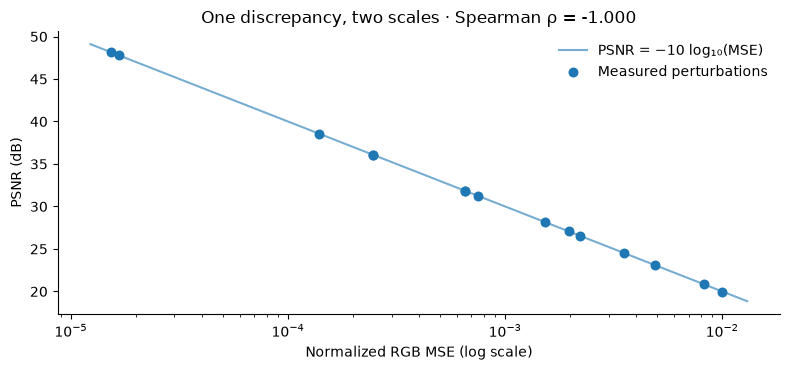


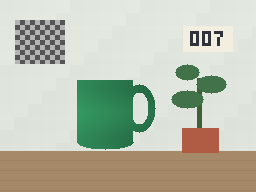
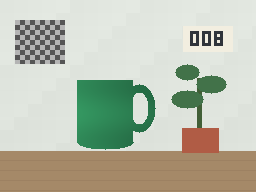
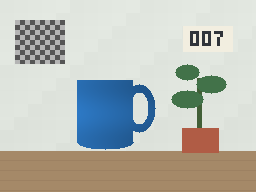

In [11]:
REFERENCE=TARGETS[6].image
PERTURBATIONS=[]
def add_variant(identifier,family,level,img):
    PERTURBATIONS.append(dict(id=identifier,family=family,level=level,image=np.asarray(img,dtype=np.uint8)))
for i,sigma in enumerate([1.0,4.0,10.0]):
    rng=np.random.default_rng(SEED+i)
    arr=np.rint(np.clip(REFERENCE.astype(np.float64)+rng.normal(0,sigma,REFERENCE.shape),0,255)).astype(np.uint8)
    add_variant(f'noise_{i}','noise',sigma,arr)
for i,offset in enumerate([1,4,12]):
    add_variant(f'brightness_{i}','brightness',offset,np.clip(REFERENCE.astype(np.int16)+offset,0,255))
for i,radius in enumerate([.4,1.0,2.0]):
    add_variant(f'blur_{i}','blur',radius,Image.fromarray(REFERENCE).filter(ImageFilter.GaussianBlur(radius)))
for i,rgb in enumerate([CUP_COLORS['blue'],CUP_COLORS['red'],(165,100,175)]):
    add_variant(f'cup_{i}','cup recolor',i+1,recolor(REFERENCE,rgb))
for i,label in enumerate(['008','009','001']):
    add_variant(f'code_{i}','tiny code',label,write_code(REFERENCE,label))
PERTURB=pd.DataFrame([dict(id=v['id'],family=v['family'],level=v['level'],
                         **image_metrics(REFERENCE,v['image'])) for v in PERTURBATIONS])
check('all comparison pairs are nonidentity',bool((PERTURB.mse>0).all()))
rank_identity=float(spearmanr(PERTURB.mse,PERTURB.psnr).statistic)
check('MSE and PSNR have reversed ranks',np.isclose(rank_identity,-1))
fig,ax=plt.subplots(figsize=(8.0,3.8))
x=np.geomspace(PERTURB.mse.min()*.8,PERTURB.mse.max()*1.3,200)
ax.plot(x,-10*np.log10(x),alpha=.6,label='PSNR = −10 log₁₀(MSE)')
ax.scatter(PERTURB.mse,PERTURB.psnr,s=38,label='Measured perturbations')
ax.set_xscale('log')
ax.set(xlabel='Normalized RGB MSE (log scale)',ylabel='PSNR (dB)',title=f'One discrepancy, two scales · Spearman ρ = {rank_identity:.3f}')
ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False)
finish(fig,'07_mse_psnr_identity')
cards([('Exact target',REFERENCE,'The shared reference for every perturbation pair.'),
       ('Small protected edit',PERTURBATIONS[-3]['image'],'Code 007 becomes 008. A small global error is still an exactness violation.'),
       ('Wrong cup color',PERTURBATIONS[9]['image'],'A meaningful color change may affect many pixels; its ranking is model-dependent.')])

## 8 · Genuine EmbeddingGemma 2, with bounded resources
The official interface is `SentenceTransformer("google/embeddinggemma-2")`. This lab uses the documented selective-encoder configuration, dictionary media inputs, and normalized embeddings. It does not generate media. [Model card](https://ai.google.dev/gemma/docs/embeddinggemma/model_card_2) · [Official multimodal guide](https://ai.google.dev/gemma/docs/embeddinggemma/multimodal-embeddinggemma-with-sentence-transformers) · [Input formats](https://sbert.net/docs/input_formats.html).

The image/text and video passes omit the audio tower; the audio pass omits the vision tower. Approximate **float32 weights alone** are 1.64 GiB (440M parameters) and 2.12 GiB (570M). Activations, loading, Python, and the operating system require additional memory. These are arithmetic estimates, **not measured M1 peak-RAM claims**. A watchdog stops a worker on excessive RSS or sustained low available memory. Subprocess exit releases its model before the next tower loads.

**Preprocessing is part of the experiment.** Media inputs have no task/instruction text. Text descriptions are encoded separately with a classification prefix. The 70-token image budget favors memory over detail; small code changes can be lost during preprocessing. The exact pixel check remains authoritative regardless of similarity. Native video inference uses all eight pre-extracted frames with their timing metadata and no file decoding. The processor expresses frame timestamps at whole-second resolution; the exact AV onset check uses the original arrays. The default image/audio passes do not construct a native joint image–audio embedding or assume that averaging separate vectors is equivalent to one.

In [12]:
# Content-addressed input registry. Identical media is encoded once.
# This saves CPU and makes reuse explicit; it is NOT a repeat-inference determinism test.
JOBS={}; ALIASES={}
def register(alias,kind,value):
    if kind=='text':
        raw=value.encode(); path=None; shape=None
    else:
        arr=np.ascontiguousarray(value)
        raw=str((arr.shape,str(arr.dtype))).encode()+arr.tobytes()
        shape=list(arr.shape)
    key=hashlib.sha256(kind.encode()+raw).hexdigest()
    if key not in JOBS:
        item=dict(key=key,kind=kind,shape=shape)
        if kind=='text': item['text']=value
        else:
            path=ASSETS/(key+'.npy'); np.save(path,arr,allow_pickle=False)
            item['path']=str(path.resolve())
        JOBS[key]=item
    ALIASES[alias]=key

for p in TRACES:
    for k,state in enumerate(TRACES[p]):
        register(f'{p}/image/{k}','image',state.image)
        if ENABLE_AUDIO_EMBEDDINGS: register(f'{p}/audio/{k}','audio',state.audio)
for v in PERTURBATIONS: register('perturb/'+v['id'],'image',v['image'])
# Fixed crops include the same spatial context across all candidates.
CUP_BOX=(68,69,160,156)
for p in TRACES:
    im=TRACES[p][6].image
    x0,y0,x1,y1=CUP_BOX
    register(f'{p}/cup/6','image',im[y0:y1,x0:x1])
for label in ('blue','red','green'):
    register('text/'+label,'text',f'A {label} coffee cup on a table.')
register('text/tone','text','A low continuous electronic tone.')
register('text/bell','text','A continuous tone with a short high pitched bell sound.')
if ENABLE_AUDIO_EMBEDDINGS:
    register('av/aligned','audio',TARGETS[3].audio)
    register('av/delayed','audio',DELAYED)
    for factor in (.5,1.5): register(f'audio/gain/{factor}','audio',(AUDIO0*factor).astype(np.float32))
if ENABLE_NATIVE_VIDEO: register('video/flash','video',VIDEO)
print(f'{len(ALIASES)} named observations → {len(JOBS)} unique model inputs.')
print(pd.Series([j['kind'] for j in JOBS.values()]).value_counts().to_string())

85 named observations → 38 unique model inputs.
image    27
audio     5
text      5
video     1


In [13]:
WORKER_SOURCE = '"""Isolated EmbeddingGemma 2 inference. Checkpoints never contain pickles."""\nfrom __future__ import annotations\nimport hashlib, json, os, re, sys, time, traceback\nfrom pathlib import Path\n\n\ndef atomic_json(path, obj):\n    temp = path.with_suffix(path.suffix + \'.tmp\')\n    temp.write_text(json.dumps(obj, indent=2), encoding=\'utf-8\')\n    os.replace(temp, path)\n\n\ndef main():\n    request_path = Path(sys.argv[1])\n    request = json.loads(request_path.read_text(encoding=\'utf-8\'))\n    outdir = request_path.parent\n    checkpoint_dir = outdir / \'checkpoints\'\n    checkpoint_dir.mkdir(exist_ok=True)\n    os.environ.update(TOKENIZERS_PARALLELISM=\'false\', OMP_NUM_THREADS=str(request[\'threads\']),\n                      MKL_NUM_THREADS=str(request[\'threads\']), OPENBLAS_NUM_THREADS=str(request[\'threads\']),\n                      HF_HUB_DISABLE_PROGRESS_BARS=\'1\', HF_HUB_ETAG_TIMEOUT=\'15\', HF_HUB_DOWNLOAD_TIMEOUT=\'60\')\n    import numpy as np\n    import torch\n    from PIL import Image\n    from sentence_transformers import SentenceTransformer\n    from huggingface_hub import HfApi, try_to_load_from_cache\n    import importlib.metadata as metadata\n\n    torch.set_num_threads(request[\'threads\'])\n    torch.set_num_interop_threads(1)\n    torch.manual_seed(request[\'seed\'])\n    torch.set_grad_enabled(False)\n    mode, device = request[\'pass\'], request[\'device\']\n    config = {\'vision_config\': None} if mode == \'audio\' else {\'audio_config\': None}\n    revision = request[\'revision\']\n    if not re.fullmatch(r\'[0-9a-f]{40}\', revision):\n        try:\n            revision = HfApi().model_info(request[\'model_id\'], revision=revision, timeout=15).sha\n        except Exception:\n            cached = try_to_load_from_cache(request[\'model_id\'], \'config.json\', revision=revision)\n            if isinstance(cached, str) and \'snapshots\' in Path(cached).parts:\n                parts = Path(cached).parts\n                revision = parts[parts.index(\'snapshots\') + 1]\n            else:\n                raise RuntimeError(\'Could not resolve an immutable model revision; check network or checkpoint cache.\')\n    if not re.fullmatch(r\'[0-9a-f]{40}\', revision):\n        raise RuntimeError(\'Resolved revision is not a 40-character hexadecimal SHA.\')\n\n    versions = {name: metadata.version(name) for name in\n                [\'torch\', \'torchvision\', \'transformers\', \'sentence-transformers\', \'numpy\', \'huggingface-hub\', \'Pillow\']}\n    t0 = time.perf_counter()\n    print(f\'Loading {mode}: {request["model_id"]}@{revision}; {device} float32\', flush=True)\n    model = SentenceTransformer(\n        request[\'model_id\'], revision=revision, device=device,\n        config_kwargs=config, trust_remote_code=False,\n        model_kwargs={\'torch_dtype\': torch.float32, \'low_cpu_mem_usage\': True,\n                      \'attn_implementation\': \'eager\'},\n    )\n    model.eval()\n    nparams = sum(p.numel() for p in model.parameters())\n    ceiling = 630_000_000 if mode == \'audio\' else 500_000_000\n    if nparams > ceiling:\n        raise RuntimeError(f\'Selective encoder loading failed: {nparams:,} parameters exceeds {ceiling:,}.\')\n    if any(p.is_floating_point() and p.dtype != torch.float32 for p in model.parameters()):\n        raise RuntimeError(\'Model parameters must be float32.\')\n    report = {\n        \'model_id\': request[\'model_id\'], \'resolved_revision\': revision,\n        \'requested_revision\': request[\'revision\'], \'pass\': mode, \'device\': device,\n        \'dtype\': \'float32\', \'parameters\': nparams, \'config_kwargs\': config,\n        \'image_soft_tokens\': request[\'image_tokens\'], \'text_prompt\': \'task: classification | query: \',\n        \'media_prompt\': \'\', \'dimension\': 768, \'normalized\': True,\n        \'input_keys\': [i[\'key\'] for i in request[\'items\']], \'measured_keys\': [],\n        \'errors\': {}, \'seconds_per_input\': {}, \'versions\': versions,\n    }\n    atomic_json(outdir / \'report.json\', report)\n    for ix, item in enumerate(request[\'items\']):\n        begin = time.perf_counter()\n        key, kind = item[\'key\'], item[\'kind\']\n        try:\n            proc = {}\n            if kind == \'text\':\n                payload, prompt = {\'text\': item[\'text\']}, \'task: classification | query: \'\n            else:\n                arr = np.load(item[\'path\'], allow_pickle=False)\n                prompt = \'\'\n                if kind == \'image\':\n                    payload = {\'image\': Image.fromarray(arr)}\n                    proc = {\'image\': {\'max_soft_tokens\': request[\'image_tokens\']}}\n                elif kind == \'audio\':\n                    if arr.ndim != 1 or arr.dtype != np.float32:\n                        raise ValueError(\'Audio must be mono float32 at the declared 16 kHz sample rate.\')\n                    payload = {\'audio\': arr}\n                    proc = {\'audio\': {\'sampling_rate\': request[\'sample_rate\']}}\n                elif kind == \'video\':\n                    payload = {\'video\': {\'array\': arr, \'video_metadata\': {\n                        \'fps\': request[\'video_fps\'], \'total_num_frames\': len(arr),\n                        \'frames_indices\': list(range(len(arr)))}}}\n                    proc = {\'video\': {\'do_sample_frames\': False, \'max_frames\': len(arr),\n                                      \'max_soft_tokens\': request[\'image_tokens\'], \'add_timestamps\': True}}\n                else:\n                    raise ValueError(f\'Unknown input kind: {kind}\')\n            with torch.inference_mode():\n                vec = model.encode(payload, prompt=prompt, batch_size=1,\n                                   show_progress_bar=False, convert_to_numpy=True,\n                                   normalize_embeddings=True, processing_kwargs=proc)\n            vec = np.asarray(vec, dtype=np.float32).reshape(-1)\n            if vec.shape != (768,) or not np.isfinite(vec).all():\n                raise RuntimeError(f\'Invalid embedding shape/values: {vec.shape}\')\n            norm = np.linalg.norm(vec)\n            if not np.isfinite(norm) or norm < 1e-8:\n                raise RuntimeError(\'Invalid embedding norm\')\n            vec /= norm\n            # An individual vector and its evidence are independently durable.\n            data = checkpoint_dir / (key + \'.npy\')\n            tmp = checkpoint_dir / (key + \'.npy.tmp\')\n            with tmp.open(\'wb\') as file:\n                np.save(file, vec, allow_pickle=False)\n            os.replace(tmp, data)\n            evidence = {k: report[k] for k in (\'model_id\', \'resolved_revision\', \'pass\', \'device\',\n                                               \'dtype\', \'versions\', \'image_soft_tokens\')}\n            evidence.update(key=key, kind=kind, checksum=hashlib.sha256(data.read_bytes()).hexdigest(),\n                            protocol=request[\'protocol\'])\n            atomic_json(checkpoint_dir / (key + \'.json\'), evidence)\n            report[\'measured_keys\'].append(key)\n            report[\'seconds_per_input\'][key] = time.perf_counter() - begin\n            if device == \'mps\' and hasattr(torch.mps, \'driver_allocated_memory\'):\n                report[\'accelerator_last_sampled_bytes\'] = int(torch.mps.driver_allocated_memory())\n            elif device == \'cuda\':\n                report[\'accelerator_peak_allocated_bytes\'] = int(torch.cuda.max_memory_allocated())\n            del payload, vec\n        except Exception as exc:\n            report[\'errors\'][key] = f\'{type(exc).__name__}: {exc}\'\n            print(f\'INPUT FAILED {kind} {key[:9]}: {report["errors"][key]}\', flush=True)\n            traceback.print_exc()\n            # One device error is enough to trigger the parent CPU retry.\n            if device != \'cpu\':\n                atomic_json(outdir / \'report.json\', report)\n                raise\n        report[\'elapsed_seconds\'] = time.perf_counter() - t0\n        atomic_json(outdir / \'report.json\', report)\n        print(f\'{mode}/{device}: {ix+1}/{len(request["items"])} complete; {len(report["errors"])} failed\', flush=True)\n    print(f\'Done: {len(report["measured_keys"])} {mode} embeddings; {len(report["errors"])} errors.\', flush=True)\n\n\nif __name__ == \'__main__\':\n    try:\n        main()\n    except Exception:\n        traceback.print_exc()\n        sys.exit(1)\n'
WORKER_FILE = ROOT / "embedding_worker.py"
WORKER_FILE.write_text(WORKER_SOURCE, encoding="utf-8")
print("Isolated inference worker ready.")


Isolated inference worker ready.


In [14]:
# Genuine model execution in a uv-managed project-local environment.
# Cache and checkpoint evidence must identify genuine, revision-consistent vectors.
import re, shutil

MODEL_REQUIREMENTS = [
    'sentence-transformers==6.2.0', 'transformers==5.19.0',
    'torch>=2.6,<3', 'torchvision>=0.21,<1', 'accelerate>=1.2,<2', 'Pillow>=10,<13',
    'numpy>=1.26,<3', 'soundfile>=0.12,<1', 'librosa>=0.10.2,<1',
]
ENV_DIR = Path.cwd() / '.venv-model'
ENV_PYTHON = ENV_DIR / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
UV = os.environ.get('EDIT_LAB_UV', 'uv')
protocol = dict(schema=2, model=MODEL_ID, requested_revision=MODEL_REVISION,
    requested_device=DEVICE, tokens=IMAGE_SOFT_TOKENS, seed=SEED, dimension=768,
    dtype='float32', sample_rate=SR, video_fps=FPS, requirements=MODEL_REQUIREMENTS,
    worker_sha256=hashlib.sha256(WORKER_SOURCE.encode()).hexdigest(),
    keys=sorted(JOBS), text_prompt='task: classification | query: ', media_prompt='')
fingerprint = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()
CACHE = ROOT / 'cache' / fingerprint
CACHE.mkdir(exist_ok=True)
EMBEDDINGS = {}
PROVENANCE = {}
MODEL_STATUS = dict(model_id=MODEL_ID, requested_revision=MODEL_REVISION, mode=MODE,
                    requested_device=DEVICE, fingerprint=fingerprint, coverage=0,
                    expected=len(JOBS), passes={}, errors=[], origin='not measured')


def valid_sha(value):
    return isinstance(value, str) and re.fullmatch(r'[0-9a-f]{40}', value) is not None


def valid_vector(value):
    return (value.shape == (768,) and np.isfinite(value).all() and
            np.isclose(np.linalg.norm(value), 1, atol=2e-5))


def valid_evidence(key, evidence, resolved=None):
    sha = evidence.get('resolved_revision')
    return (key in JOBS and evidence.get('key') == key and evidence.get('kind') == JOBS[key]['kind']
            and evidence.get('pass') == ('audio' if JOBS[key]['kind'] == 'audio' else 'video' if JOBS[key]['kind'] == 'video' else 'vision')
            and evidence.get('model_id') == MODEL_ID and valid_sha(sha)
            and (resolved is None or sha == resolved)
            and (not valid_sha(MODEL_REVISION) or sha == MODEL_REVISION)
            and evidence.get('protocol') == fingerprint and evidence.get('dtype') == 'float32'
            and evidence.get('device') in ('cpu', 'mps', 'cuda')
            and evidence.get('image_soft_tokens') == IMAGE_SOFT_TOKENS
            and isinstance(evidence.get('versions'), dict) and bool(evidence['versions']))


def cache_load():
    meta_path, data_path = CACHE / 'metadata.json', CACHE / 'embeddings.npz'
    if not (meta_path.exists() and data_path.exists()):
        return False
    try:
        meta = json.loads(meta_path.read_text(encoding='utf-8'))
        sha = meta.get('resolved_revision')
        status = meta['status']
        if (meta['fingerprint'] != fingerprint or not valid_sha(sha) or
            status.get('resolved_revision') != sha or
            (valid_sha(MODEL_REVISION) and sha != MODEL_REVISION) or
            hashlib.sha256(data_path.read_bytes()).hexdigest() != meta['vectors_sha256']):
            raise ValueError('fingerprint, revision, or checksum mismatch')
        with np.load(data_path, allow_pickle=False) as archive:
            recovered = {key: archive[key].astype(np.float32) for key in archive.files}
        evidence = meta['provenance']
        if set(recovered) != set(evidence) or not all(
            valid_evidence(key, evidence[key], sha) and valid_vector(value)
            for key, value in recovered.items()
        ):
            raise ValueError('invalid vector or inconsistent provenance')
        EMBEDDINGS.update(recovered)
        PROVENANCE.update(evidence)
        MODEL_STATUS.update(status)
        MODEL_STATUS.update(mode=MODE, origin='validated local cache', coverage=len(EMBEDDINGS))
        return True
    except Exception as exc:
        MODEL_STATUS['errors'].append('Cache rejected: ' + str(exc))
        return False


def cache_save():
    if not EMBEDDINGS:
        return
    target = CACHE / 'embeddings.npz'
    temp = CACHE / 'embeddings.npz.tmp'
    with temp.open('wb') as file:
        np.savez_compressed(file, **EMBEDDINGS)
    os.replace(temp, target)
    meta = dict(fingerprint=fingerprint, resolved_revision=MODEL_STATUS.get('resolved_revision'),
                vectors_sha256=hashlib.sha256(target.read_bytes()).hexdigest(),
                provenance=PROVENANCE, status=MODEL_STATUS)
    temp_meta = CACHE / 'metadata.json.tmp'
    temp_meta.write_text(json.dumps(meta, indent=2), encoding='utf-8')
    os.replace(temp_meta, CACHE / 'metadata.json')


def stop_process(proc):
    # Process groups preserve cleanup even if a sandbox denies process enumeration.
    import signal
    children = []
    try:
        children = psutil.Process(proc.pid).children(recursive=True)
    except (psutil.Error, OSError):
        pass
    for child in children:
        try: child.terminate()
        except (psutil.Error, OSError): pass
    try:
        if os.name != 'nt':
            os.killpg(proc.pid, signal.SIGTERM)
        else:
            proc.terminate()
    except (ProcessLookupError, PermissionError):
        if proc.poll() is None: proc.terminate()
    try:
        proc.wait(timeout=5)
    except subprocess.TimeoutExpired:
        if os.name != 'nt':
            try: os.killpg(proc.pid, signal.SIGKILL)
            except ProcessLookupError: pass
        else:
            proc.kill()
        proc.wait(timeout=5)
    # A descendant may still be alive after its parent has exited.
    if os.name != 'nt':
        try: os.killpg(proc.pid, signal.SIGKILL)
        except (ProcessLookupError, PermissionError): pass
    for child in children:
        try:
            if child.is_running(): child.kill()
        except (psutil.Error, OSError): pass


def guarded_process(command, logfile, timeout_seconds=3600, guard_memory=True):
    peak = 0; low_count = 0; began = time.monotonic(); reason = None
    env = os.environ.copy()
    env.update(OMP_NUM_THREADS=str(CPU_THREADS), MKL_NUM_THREADS=str(CPU_THREADS),
               OPENBLAS_NUM_THREADS=str(CPU_THREADS), TOKENIZERS_PARALLELISM='false')
    with open(logfile, 'w', encoding='utf-8') as log:
        proc = subprocess.Popen(command, stdout=log, stderr=subprocess.STDOUT, env=env,
                                start_new_session=(os.name != 'nt'))
        try:
            while proc.poll() is None:
                if time.monotonic() - began > timeout_seconds:
                    reason = 'time limit'; stop_process(proc); break
                if guard_memory:
                    try:
                        root = psutil.Process(proc.pid)
                        rss = 0
                        for child in [root] + root.children(recursive=True):
                            try: rss += child.memory_info().rss
                            except psutil.NoSuchProcess: pass
                        peak = max(peak, rss)
                        available = psutil.virtual_memory().available / 2**30
                        low_count = low_count + 1 if available < MIN_FREE_GIB else 0
                        if rss / 2**30 > WORKER_RSS_LIMIT_GIB or low_count >= 4:
                            reason = 'memory safety guard'; stop_process(proc); break
                    except psutil.NoSuchProcess:
                        pass  # The worker may have exited between poll and sampling.
                    except (psutil.Error, OSError) as exc:
                        # Do not continue an inference without its memory guard.
                        reason = f'memory monitoring unavailable: {type(exc).__name__}'
                        stop_process(proc); break
                time.sleep(.7)
        except BaseException:
            stop_process(proc)
            raise
    return dict(returncode=proc.returncode, stop_reason=reason,
                peak_tree_rss_gib=peak / 2**30, elapsed_seconds=time.monotonic()-began, log=str(logfile))


def prepare_environment():
    def usable():
        if not ENV_PYTHON.exists():
            return False
        code = ("import importlib.metadata as m; "
                "assert m.version('sentence-transformers')=='6.2.0'; "
                "assert m.version('transformers')=='5.19.0'; "
                "[m.version(x) for x in ('torch','torchvision','accelerate','Pillow','numpy','soundfile','librosa')]")
        try:
            r = subprocess.run([str(ENV_PYTHON), '-c', code], capture_output=True, text=True, timeout=30)
            if r.returncode: return False
            return subprocess.run([UV, 'pip', 'check', '--python', str(ENV_PYTHON)],
                                  capture_output=True, text=True, timeout=90).returncode == 0
        except (OSError, subprocess.TimeoutExpired):
            return False
    if usable(): return True
    if not AUTO_INSTALL_MODEL:
        MODEL_STATUS['errors'].append('Model environment is absent or invalid and AUTO_INSTALL_MODEL=False.')
        return False
    print('Preparing isolated model dependencies with uv; details in model_install.log.')
    if not ENV_PYTHON.exists():
        result = guarded_process([UV, 'venv', '--python', sys.executable, str(ENV_DIR)],
                                 ROOT / 'model_venv.log', timeout_seconds=300, guard_memory=False)
        if result['returncode']:
            MODEL_STATUS['errors'].append('Model environment creation failed; see model_venv.log.')
            return False
    command = [UV, 'pip', 'install', '--python', str(ENV_PYTHON)]
    if platform.system() in ('Linux', 'Windows'):
        command += ['--torch-backend', 'auto']
    command += MODEL_REQUIREMENTS
    result = guarded_process(command, ROOT / 'model_install.log', timeout_seconds=3600, guard_memory=False)
    MODEL_STATUS['installation'] = result
    if result['returncode'] != 0 or not usable():
        MODEL_STATUS['errors'].append('Model dependency installation or validation failed; see model_install.log.')
        return False
    return True


def detect_device():
    code = ("import json,torch; print(json.dumps({'cuda':torch.cuda.is_available(), "
            "'mps':hasattr(torch.backends,'mps') and torch.backends.mps.is_available()}))")
    result = subprocess.run([str(ENV_PYTHON), '-c', code], capture_output=True, text=True, timeout=90, check=True)
    available = json.loads(result.stdout.strip().splitlines()[-1])
    selected = ('cuda' if available['cuda'] else 'mps' if available['mps'] else 'cpu') if DEVICE == 'auto' else DEVICE
    if selected != 'cpu' and not available.get(selected, False):
        MODEL_STATUS['errors'].append(f'{selected} is unavailable; falling back to CPU.')
        selected = 'cpu'
    MODEL_STATUS['device_probe'] = available
    return selected


def load_checkpoints(pass_dir, expected_keys):
    restored = 0
    folder = pass_dir / 'checkpoints'
    for key in expected_keys:
        data, meta = folder / (key + '.npy'), folder / (key + '.json')
        if not (data.exists() and meta.exists()): continue
        try:
            evidence = json.loads(meta.read_text(encoding='utf-8'))
            resolved = MODEL_STATUS.get('resolved_revision')
            if not valid_evidence(key, evidence, resolved) or evidence['device'] != pass_dir.name:
                raise ValueError('provenance mismatch')
            if hashlib.sha256(data.read_bytes()).hexdigest() != evidence['checksum']:
                raise ValueError('checksum mismatch')
            value = np.load(data, allow_pickle=False).astype(np.float32)
            if not valid_vector(value): raise ValueError('invalid vector')
            MODEL_STATUS['resolved_revision'] = evidence['resolved_revision']
            EMBEDDINGS[key] = value
            PROVENANCE[key] = evidence
            restored += 1
        except Exception as exc:
            MODEL_STATUS['errors'].append(f'{key[:10]} checkpoint rejected: {exc}')
    return restored


have_cache = cache_load() if MODE in ('auto', 'offline') else False
if len(EMBEDDINGS) < len(JOBS) and MODE != 'offline':
    try:
        if prepare_environment():
            device = detect_device()
            for pass_name, kinds in [('vision', {'image', 'text'}), ('audio', {'audio'}), ('video', {'video'})]:
                pass_keys = {key for key, job in JOBS.items() if job['kind'] in kinds}
                if not pass_keys: continue
                pass_status = MODEL_STATUS['passes'].setdefault(pass_name, {'attempts': []})
                devices = [device] if device == 'cpu' else [device, 'cpu']
                for attempt_device in devices:
                    pending = pass_keys - EMBEDDINGS.keys()
                    if not pending: break
                    pass_dir = CACHE / pass_name / attempt_device
                    pass_dir.mkdir(parents=True, exist_ok=True)
                    if MODE != 'live':
                        load_checkpoints(pass_dir, pending)
                        pending = pass_keys - EMBEDDINGS.keys()
                        if not pending: break
                    # Clear just the requested items to avoid accepting stale output from this attempt.
                    checkpoint_dir = pass_dir / 'checkpoints'
                    for key in pending:
                        for suffix in ('.npy', '.json'):
                            path = checkpoint_dir / (key + suffix)
                            if path.exists(): path.unlink()
                    if psutil.virtual_memory().available / 2**30 < 2.8:
                        MODEL_STATUS['errors'].append(f'{pass_name}: under 2.8 GiB available before loading; skipped for safety.')
                        break
                    items = [JOBS[key] for key in sorted(pending)]
                    request = dict(model_id=MODEL_ID, revision=MODEL_STATUS.get('resolved_revision', MODEL_REVISION),
                                   **{'pass': pass_name}, device=attempt_device, items=items, protocol=fingerprint,
                                   threads=CPU_THREADS, seed=SEED, image_tokens=IMAGE_SOFT_TOKENS,
                                   sample_rate=SR, video_fps=FPS)
                    request_file = pass_dir / 'request.json'
                    request_file.write_text(json.dumps(request), encoding='utf-8')
                    report_path = pass_dir / 'report.json'
                    if report_path.exists(): report_path.unlink()
                    print(f'EmbeddingGemma 2: {pass_name} on {attempt_device}, {len(items)} inputs, batch size 1.')
                    result = guarded_process([str(ENV_PYTHON), str(WORKER_FILE.resolve()), str(request_file.resolve())],
                                             pass_dir / 'worker.log', timeout_seconds=1800 if attempt_device != 'cpu' else 3600)
                    if report_path.exists():
                        try:
                            report = json.loads(report_path.read_text(encoding='utf-8'))
                            sha = report.get('resolved_revision')
                            if (not valid_sha(sha) or report.get('model_id') != MODEL_ID or
                                report.get('pass') != pass_name or report.get('device') != attempt_device or
                                set(report.get('input_keys', [])) != pending or
                                (MODEL_STATUS.get('resolved_revision') and sha != MODEL_STATUS['resolved_revision']) or
                                (valid_sha(MODEL_REVISION) and sha != MODEL_REVISION)):
                                raise ValueError('inconsistent worker report')
                            MODEL_STATUS['resolved_revision'] = sha
                            result['report'] = report
                        except Exception as exc:
                            result['report_error'] = str(exc)
                    restored = load_checkpoints(pass_dir, pending)
                    result['validated_checkpoints'] = restored
                    pass_status['attempts'].append(result)
                    MODEL_STATUS['coverage'] = len(EMBEDDINGS)
                    if EMBEDDINGS:
                        MODEL_STATUS['origin'] = 'validated cache plus live local inference' if have_cache else 'live local inference'
                        cache_save()
                    if result['returncode'] != 0 or restored < len(items):
                        message = f'{pass_name}/{attempt_device}: incomplete ({result["stop_reason"] or "worker error"}); see {pass_dir / "worker.log"}.'
                        MODEL_STATUS['errors'].append(message)
                        if attempt_device != 'cpu':
                            device = 'cpu'
                            print(message + ' Retrying remaining inputs on CPU.')
                    gc.collect()
    except Exception as exc:
        MODEL_STATUS['errors'].append(f'{type(exc).__name__}: {exc}')
elif MODE == 'offline' and len(EMBEDDINGS) < len(JOBS):
    MODEL_STATUS['errors'].append('Offline mode: missing model inputs were not computed.')

MODEL_STATUS['coverage'] = len(EMBEDDINGS)
MODEL_STATUS['expected'] = len(JOBS)
cache_save()
(ROOT / 'model_status.json').write_text(json.dumps(MODEL_STATUS, indent=2), encoding='utf-8')
if len(EMBEDDINGS) == len(JOBS):
    note('Real EmbeddingGemma 2 evidence ready',
         f'{len(EMBEDDINGS)} unique vectors · {MODEL_STATUS["origin"]} · revision {MODEL_STATUS.get("resolved_revision")}')
else:
    note('Model evidence is incomplete — never replaced with a proxy',
         f'{len(EMBEDDINGS)}/{len(JOBS)} inputs available. ' +
         (' '.join(MODEL_STATUS['errors'][-2:]) or 'See model_status.json.'))
if STRICT_MODEL and len(EMBEDDINGS) != len(JOBS):
    raise RuntimeError('STRICT_MODEL requires all real embeddings. Inspect model_status.json and worker logs.')


## 9 · Embedding distance versus MSE, SSIM, and PSNR
For unit embeddings, the cosine distance is
\[
d_{\cos}(x,y)=1-z_x^\top z_y=\tfrac12\|z_x-z_y\|_2^2.
\]
It is a different geometry, not a rescaled MSE. Small cosine distance is not a certificate of equality; cosine distance itself also need not obey the triangle inequality. No universal relationship or human agreement is inferred here.

Each figure below is a **single plot** of the same measured pairs. MSE and PSNR should give reversed rank correlations with cosine distance; SSIM can disagree. Pearson correlations need not have that exact relationship. If inference is unavailable, these plots are omitted rather than fabricated.

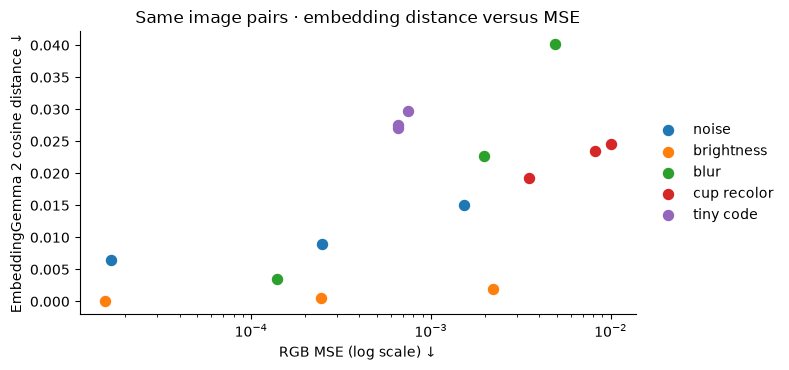

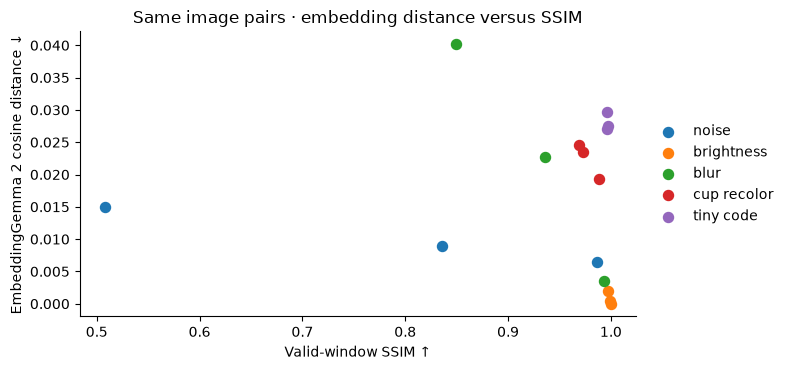

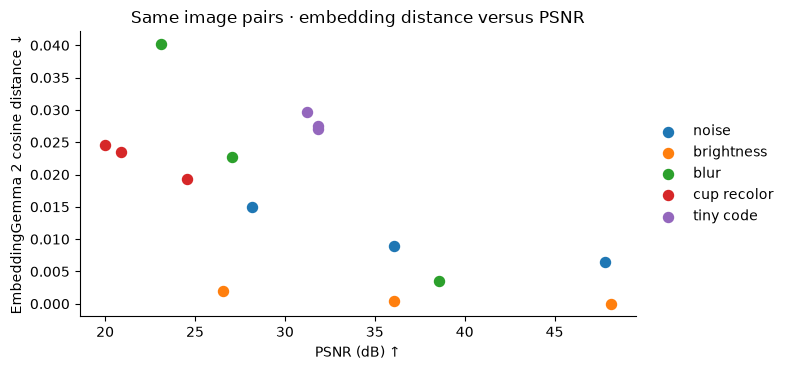

metric,n,Pearson,Spearman
MSE,15,0.459,0.563
PSNR,15,-0.637,-0.563
SSIM,15,-0.092,-0.350


In [15]:
def embedding(alias):
    key=ALIASES.get(alias)
    return EMBEDDINGS.get(key) if key else None

def cosine_distance(a,b):
    if a is None or b is None: return np.nan
    aa=np.asarray(a,dtype=np.float64); bb=np.asarray(b,dtype=np.float64)
    aa=aa/np.linalg.norm(aa); bb=bb/np.linalg.norm(bb)
    return float(np.clip(1-np.dot(aa,bb),0,2))

def unavailable(section):
    note(section+' · NOT MEASURED',
         'Real embeddings are unavailable for these inputs. No substitute metric or invented model output is shown. '
         'Use MODE="auto" with internet, or a matching cache; details are in model_status.json and worker logs.')

reference_embedding=embedding('exact/image/6')
EMBED_COMPARE=PERTURB.copy()
EMBED_COMPARE['cosine_distance']=[cosine_distance(reference_embedding,embedding('perturb/'+i)) for i in PERTURB.id]
CORRELATIONS=pd.DataFrame(columns=['metric','n','Pearson','Spearman'])
if EMBED_COMPARE.cosine_distance.notna().all():
    for metric,xlabel,scale in [('mse','RGB MSE (log scale) ↓','log'),
                                ('ssim','Valid-window SSIM ↑','linear'),
                                ('psnr','PSNR (dB) ↑','linear')]:
        fig,ax=plt.subplots(figsize=(8.0,3.8))
        for family,g in EMBED_COMPARE.groupby('family',sort=False):
            ax.scatter(g[metric],g.cosine_distance,s=52,label=family)
        ax.set_xscale(scale)
        ax.set(xlabel=xlabel,ylabel='EmbeddingGemma 2 cosine distance ↓',
               title=f'Same image pairs · embedding distance versus {metric.upper()}')
        ax.legend(frameon=False,loc='center left',bbox_to_anchor=(1.01,.5))
        ax.spines[['top','right']].set_visible(False)
        finish(fig,'08_embedding_vs_'+metric)
    corr=[]
    for metric in ['mse','psnr','ssim']:
        x=EMBED_COMPARE[metric].to_numpy(); y=EMBED_COMPARE.cosine_distance.to_numpy()
        finite=np.isfinite(x)&np.isfinite(y); x=x[finite];y=y[finite]
        defined=len(x)>2 and np.ptp(x)>0 and np.ptp(y)>0
        corr.append(dict(metric=metric.upper(),n=len(x),
                         Pearson=float(pearsonr(x,y).statistic) if defined else np.nan,
                         Spearman=float(spearmanr(x,y).statistic) if defined else np.nan))
    CORRELATIONS=pd.DataFrame(corr)
    table(CORRELATIONS,{'Pearson':'{:.3f}','Spearman':'{:.3f}'})
    note('Do not read this as human agreement',
         'These 15 synthetic perturbations share one reference. No human labels, significance tests, or independent-sample '
         'confidence intervals are claimed. Change the perturbation mix and the aggregate correlation can change.')
else:
    unavailable('Embedding–pixel correlation')

### Whole-image versus object-local evidence
The following comparison uses the same rectangular cup crop for every output. A crop is evidence about that object and surrounding context, **not** a mask-exact certificate. The exact image and drift image have identical cup pixels; the forgotten and no-op images have the same wrong cup. The real model's magnitude of response is left to measurement.

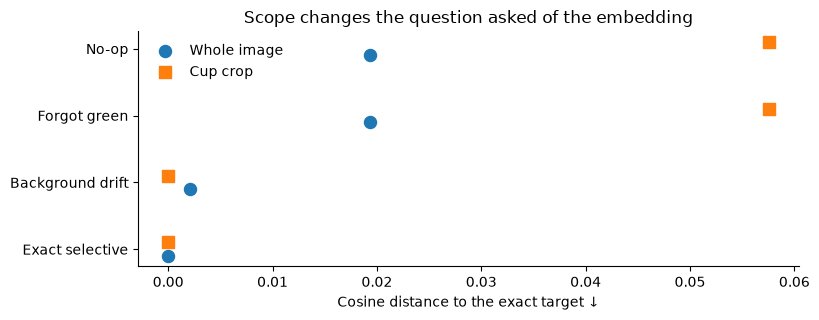

policy,full_image,cup_crop,cup_exact,protected_exact
Exact selective,0.00000,0.00000,True,True
Background drift,0.00204,0.00000,True,False
Forgot green,0.01933,0.05756,False,True
No-op,0.01933,0.05756,False,True


In [16]:
LOCAL_ROWS=[]
for p in ('exact','drift','forget','no-op'):
    LOCAL_ROWS.append(dict(policy=POLICY_LABEL[p],
        full_image=cosine_distance(embedding('exact/image/6'),embedding(f'{p}/image/6')),
        cup_crop=cosine_distance(embedding('exact/cup/6'),embedding(f'{p}/cup/6')),
        cup_exact=np.array_equal(TRACES[p][6].image[CUP],REFERENCE[CUP]),
        protected_exact=np.array_equal(TRACES[p][6].image[STATIC],IMAGE0[STATIC])))
LOCAL=pd.DataFrame(LOCAL_ROWS)
if LOCAL[['full_image','cup_crop']].notna().all().all():
    fig,ax=plt.subplots(figsize=(8.3,3.3))
    pos=np.arange(len(LOCAL))
    ax.scatter(LOCAL.full_image,pos-.10,s=75,label='Whole image')
    ax.scatter(LOCAL.cup_crop,pos+.10,s=75,marker='s',label='Cup crop')
    ax.set(yticks=pos,yticklabels=LOCAL.policy,xlabel='Cosine distance to the exact target ↓',
           title='Scope changes the question asked of the embedding')
    ax.legend(frameon=False);ax.spines[['top','right']].set_visible(False)
    finish(fig,'09_whole_vs_local')
    table(LOCAL,{'full_image':'{:.5f}','cup_crop':'{:.5f}'})
else:
    table(LOCAL[['policy','cup_exact','protected_exact']])
    unavailable('Whole-image / cup-crop embeddings')

## 10 · Embeddings along the trajectory
The first plot reports **distance to each modality's original asset**, not success. It should not be interpreted as a target trajectory: intentional edits can move away from the source, and an authorized reversion can move back.

The second plot is a two-dimensional PCA illustration of measured image embeddings. The retained variance is reported. Projected distances and arrows are not a validity score; the ledger, not the path's shape, decides whether a transition is allowed.

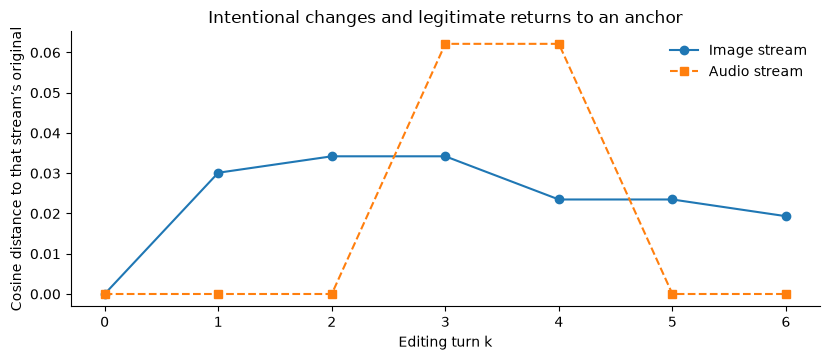

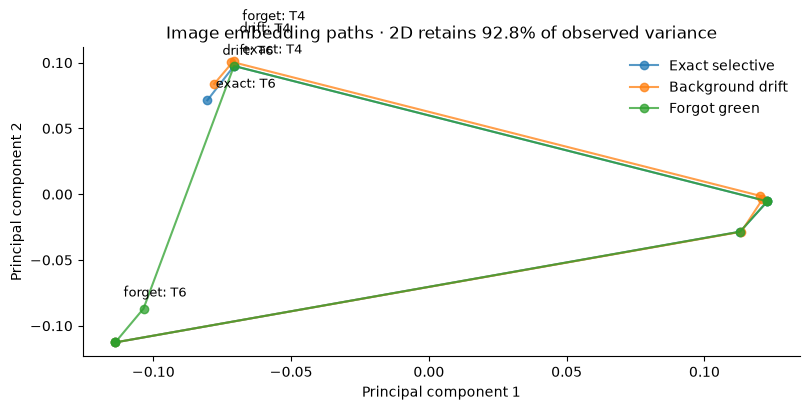

In [17]:
TRAJECTORY_EMBED=[]
for p in ('exact','drift','forget'):
    for k in range(7):
        TRAJECTORY_EMBED.append(dict(policy=p,turn=k,
            image=cosine_distance(embedding('exact/image/0'),embedding(f'{p}/image/{k}')),
            audio=cosine_distance(embedding('exact/audio/0'),embedding(f'{p}/audio/{k}'))))
TRAJECTORY_EMBED=pd.DataFrame(TRAJECTORY_EMBED)
g=TRAJECTORY_EMBED[TRAJECTORY_EMBED.policy=='exact']
if g.image.notna().all():
    fig,ax=plt.subplots(figsize=(8.4,3.7))
    ax.plot(g.turn,g.image,'o-',label='Image stream')
    if g.audio.notna().all(): ax.plot(g.turn,g.audio,'s--',label='Audio stream')
    ax.set(xticks=range(7),xlabel='Editing turn k',ylabel='Cosine distance to that stream’s original',
           title='Intentional changes and legitimate returns to an anchor')
    ax.legend(frameon=False);ax.spines[['top','right']].set_visible(False)
    finish(fig,'10_multimodal_trajectory')
else:
    unavailable('Modality-specific embedding trajectories')

aliases=[f'{p}/image/{k}' for p in ('exact','drift','forget') for k in range(7)]
vectors=[embedding(a) for a in aliases]
if all(v is not None for v in vectors):
    Z=np.vstack(vectors).astype(np.float64); center=Z.mean(axis=0)
    U,S,Vt=np.linalg.svd(Z-center,full_matrices=False)
    XY=(Z-center)@Vt[:2].T
    variance=float(np.sum(S[:2]**2)/np.sum(S**2)) if np.sum(S**2)>0 else np.nan
    fig,ax=plt.subplots(figsize=(8.2,4.2))
    for pi,p in enumerate(('exact','drift','forget')):
        xy=XY[7*pi:7*(pi+1)]
        ax.plot(xy[:,0],xy[:,1],'-o',alpha=.75,label=POLICY_LABEL[p])
        for k in (4,6):
            ax.annotate(f'{p}: T{k}',tuple(xy[k]),xytext=(6,9+pi*12),textcoords='offset points',fontsize=9)
    ax.set(xlabel='Principal component 1',ylabel='Principal component 2',
           title=f'Image embedding paths · 2D retains {variance:.1%} of observed variance')
    ax.legend(frameon=False,loc='best');ax.spines[['top','right']].set_visible(False)
    finish(fig,'11_embedding_paths')
else:
    unavailable('PCA embedding path')

### Separate semantic hints from exact predicates
Text–image similarity asks whether a representation aligns with a description. It does not prove that **every** protected sample is unchanged. The descriptions below are not concatenated into the image inputs, so a matching instruction cannot manufacture its own image evidence.

For audio, the aligned and delayed clips have the same type of event but different timing. Their measured cosine similarity is shown beside the exact timing predicate; no claim is made that a high similarity validates synchronization. Image–audio similarity is not scored in the main cup story because no relationship was prescribed.

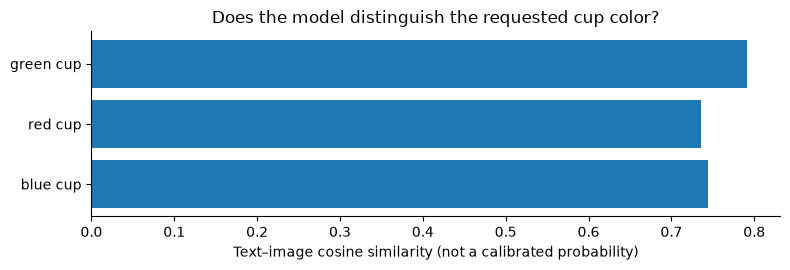

comparison,cosine_distance,waveform_mse
Original vs bell,0.06215,0.0003304
Aligned vs delayed bell,0.00969,0.0006607
Original vs half gain,0.00517,0.0001531


In [18]:
TEXT_ROWS=[]
for color in ('blue','red','green'):
    d=cosine_distance(embedding('text/'+color),embedding('exact/cup/6'))
    TEXT_ROWS.append(dict(description=f'A {color} coffee cup on a table.',cosine_similarity=1-d if np.isfinite(d) else np.nan))
TEXT_ALIGNMENT=pd.DataFrame(TEXT_ROWS)
if TEXT_ALIGNMENT.cosine_similarity.notna().all():
    fig,ax=plt.subplots(figsize=(8.0,2.8))
    ax.barh(['blue cup','red cup','green cup'],TEXT_ALIGNMENT.cosine_similarity)
    ax.set(xlabel='Text–image cosine similarity (not a calibrated probability)',
           title='Does the model distinguish the requested cup color?')
    ax.spines[['top','right']].set_visible(False)
    finish(fig,'12_text_alignment')
else: unavailable('Text–image semantic hints')

AUDIO_EMBED_TABLE=pd.DataFrame([
 {'comparison':'Original vs bell','cosine_distance':cosine_distance(embedding('exact/audio/0'),embedding('av/aligned')),
  'waveform_mse':float(np.mean((AUDIO0.astype(np.float64)-TARGETS[3].audio.astype(np.float64))**2))},
 {'comparison':'Aligned vs delayed bell','cosine_distance':cosine_distance(embedding('av/aligned'),embedding('av/delayed')),
  'waveform_mse':float(np.mean((TARGETS[3].audio.astype(np.float64)-DELAYED.astype(np.float64))**2))},
 {'comparison':'Original vs half gain','cosine_distance':cosine_distance(embedding('exact/audio/0'),embedding('audio/gain/0.5')),
  'waveform_mse':float(np.mean((AUDIO0.astype(np.float64)-(AUDIO0*.5).astype(np.float64))**2))},
])
if AUDIO_EMBED_TABLE.cosine_distance.notna().all():
    table(AUDIO_EMBED_TABLE,{'cosine_distance':'{:.5f}','waveform_mse':'{:.7f}'})
else:
    table(AUDIO_EMBED_TABLE[['comparison','waveform_mse']],{'waveform_mse':'{:.7f}'})
    unavailable('Audio embeddings')

if ENABLE_NATIVE_VIDEO:
    v=embedding('video/flash')
    note('Optional native video',
         f'Real visual-only video embedding: {len(v)} dimensions.' if v is not None else
         'NOT MEASURED. The timing tests above still use the exact source arrays. See the video worker error log.')

## 11 · A typed trajectory diff, without a paid judge
This mirrors the survey's **Jev-style** decomposition: one typed decision per requirement, explicit evidence and references, and an `UNKNOWN` state when evidence is absent. The implementation below is an **exact deterministic checker**, not a Jev or LLM call. Cosine similarity is never presented as a calibrated probability.

At turn 5, restoring original audio is the authorized specification change. Returning the cup to blue is an observed but unauthorized change. The green requirement was satisfied at turn 4 and fails at turn 5: **forgetting**, not “never achieved,” and not a legitimate override.

In [19]:
class Verdict(str,Enum):
    PASS='PASS'; FAIL='FAIL'; UNKNOWN='UNKNOWN'

def typed_check(media,c):
    actual=pixels(media,c.property); target=pixels(TARGETS[c.reference_turn],c.property)
    if actual.shape!=target.shape:
        return dict(id=c.identifier,verdict=Verdict.UNKNOWN.value,reason='Correspondence unavailable')
    error=float(np.max(np.abs(actual.astype(np.float64)-target.astype(np.float64))))
    return dict(id=c.identifier,verdict=Verdict.PASS.value if np.array_equal(actual,target) else Verdict.FAIL.value,
                evidence='exact array comparison',max_absolute_error=error,
                units='audio amplitude' if c.property=='audio' else 'RGB code values',
                reference_revision=c.reference_turn,probability=None)

before,after=TRACES['forget'][4:6]
newly_breached=[]
for c in active(5):
    if c.born<5 and satisfied(before,c) and not satisfied(after,c): newly_breached.append(c.identifier)
DIFF=dict(turn=5,authorized_update={'property':'audio','target_reference':0,'action':'revert'},
          observed_changed_properties=[p for p in PROPERTIES if not np.array_equal(pixels(before,p),pixels(after,p))],
          newly_breached=newly_breached,retired=['audio.bell.v1'],
          decisions=[typed_check(after,c) for c in active(5)])
print(json.dumps(DIFF,indent=2))
check('trajectory diff detects forgetting',DIFF['newly_breached']==['cup.green.v2'])
check('probability is never fabricated',all(d.get('probability') is None for d in DIFF['decisions']))

{
  "turn": 5,
  "authorized_update": {
    "property": "audio",
    "target_reference": 0,
    "action": "revert"
  },
  "observed_changed_properties": [
    "cup",
    "audio"
  ],
  "newly_breached": [
    "cup.green.v2"
  ],
  "retired": [
    "audio.bell.v1"
  ],
  "decisions": [
    {
      "id": "cup.green.v2",
      "verdict": "FAIL",
      "evidence": "exact array comparison",
      "max_absolute_error": 100.0,
      "units": "RGB code values",
      "reference_revision": 4,
      "probability": null
    },
    {
      "id": "patch.contrast.v1",
      "verdict": "PASS",
      "evidence": "exact array comparison",
      "max_absolute_error": 0.0,
      "units": "RGB code values",
      "reference_revision": 2,
      "probability": null
    },
    {
      "id": "audio.original.v2",
      "verdict": "PASS",
      "evidence": "exact array comparison",
      "max_absolute_error": 0.0,
      "units": "audio amplitude",
      "reference_revision": 0,
      "probability": null
    },


## 12 · Reproducibility checks and exports
Tests cover exact compositing, mask/window semantics, protected audio, overrides, reversions, drift accumulation, endpoint ambiguity, and the MSE–PSNR identity. Real embeddings, when present, are checked for finite values, unit norm, 768-dimensional shape, and revision provenance. Model measurements are never included in the core test count unless they actually ran.

Exports include CSV measurements, a JSON trajectory diff, model logs, content-addressed input arrays, SVG/PNG figures, and a run manifest. Model weights and the isolated environment are **not** bundled in the exports. The model's normal Hugging Face cache and this notebook's embedding cache remain on your machine for later offline use.

In [20]:
if EMBEDDINGS:
    check('real embeddings finite',all(np.isfinite(v).all() for v in EMBEDDINGS.values()))
    check('real embeddings have 768 dimensions',all(v.shape==(768,) for v in EMBEDDINGS.values()))
    check('real embeddings normalized',all(np.isclose(np.linalg.norm(v),1,atol=2e-5) for v in EMBEDDINGS.values()))
check('current instruction succeeds but history fails at forgetting',
      RESULTS.query("policy == 'forget' and turn == 5").iloc[0].I==1 and
      RESULTS.query("policy == 'forget' and turn == 5").iloc[0].H<1)
check('no-op has perfect source PSNR but fails final spec',
      np.isposinf(RESULTS.query("policy == 'no-op' and turn == 6").iloc[0].source_psnr) and
      not bool(RESULTS.query("policy == 'no-op' and turn == 6").iloc[0].all_active))
check('static protection never breaks in exact trace',bool((RESULTS.query("policy == 'exact'").protected_max==0).all()))

for name,frame in [('trajectory_metrics',RESULTS),('perturbation_metrics',EMBED_COMPARE),
                   ('metric_correlations',CORRELATIONS),('localized_embeddings',LOCAL),
                   ('embedding_trajectories',TRAJECTORY_EMBED),('audio_embeddings',AUDIO_EMBED_TABLE),
                   ('text_alignment',TEXT_ALIGNMENT),('av_consistency',AV_TABLE)]:
    frame.to_csv(ROOT/(name+'.csv'),index=False)
(ROOT/'trajectory_diff.json').write_text(json.dumps(DIFF,indent=2))
versions={name:metadata.version(name) for name in ['numpy','pandas','matplotlib','scipy','scikit-image','Pillow','psutil']}
manifest=dict(created_at=datetime.now(timezone.utc).isoformat(),seed=SEED,
              system=dict(os=platform.system(),machine=platform.machine(),python=platform.python_version()),
              kernel_packages=versions,mode=MODE,model=MODEL_STATUS,
              fixture=dict(image_shape=list(IMAGE0.shape),image_sha256=hashlib.sha256(IMAGE0.tobytes()).hexdigest(),
                           audio_samples=len(AUDIO0),sample_rate=SR,source_audio_sha256=hashlib.sha256(AUDIO0.tobytes()).hexdigest()),
              metric_protocol=dict(image_range=[0,1],psnr_peak=1,ssim_window=7,ssim_kernel='uniform',
                    ssim_support='only centers with complete 7x7 support inside mask',audio_ssim='not used'),
              tests=CHECKS,elapsed_seconds=round(time.perf_counter()-RUN_STARTED,2),
              limitations=['Single synthetic source; no human agreement estimate',
                           'Worker process RSS is recorded; GPU memory is not fully represented by RSS',
                           'Embedding availability is explicitly logged; no proxy fallback'])
(ROOT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
(ROOT/'test_results.json').write_text(json.dumps(dict(passed=len(CHECKS),checks=CHECKS),indent=2))
print(f'{len(CHECKS)} assertions passed.')
print(f'Model inputs measured or cached: {len(EMBEDDINGS)} / {len(JOBS)}')
print(f'Artifacts: {ROOT.resolve()}')
for name in ('run_manifest.json','trajectory_metrics.csv','perturbation_metrics.csv','trajectory_diff.json'):
    display(FileLink(str(Path('edit_fidelity_outputs')/name)))

32 assertions passed.
Model inputs measured or cached: 38 / 38
Artifacts: /Users/oguz/Downloads/EmbeddingGemma2_Edit_Fidelity_Lab/edit_fidelity_outputs


/Users/oguz/Downloads/EmbeddingGemma2_Edit_Fidelity_Lab/edit_fidelity_outputs/run_manifest.json

/Users/oguz/Downloads/EmbeddingGemma2_Edit_Fidelity_Lab/edit_fidelity_outputs/trajectory_metrics.csv

/Users/oguz/Downloads/EmbeddingGemma2_Edit_Fidelity_Lab/edit_fidelity_outputs/perturbation_metrics.csv

/Users/oguz/Downloads/EmbeddingGemma2_Edit_Fidelity_Lab/edit_fidelity_outputs/trajectory_diff.json

---
## What to take away
**Specifications define correctness.** Exact copying enforces preservation. MSE and PSNR measure the same squared error on different scales; SSIM measures a different structural relationship. Embeddings add learned semantic evidence, but do not decide which old instruction remains active. Audio/video synchronization requires an explicit relation over media time, not just a similarity between pooled vectors.

**No-op is not fidelity.** The untouched source can have infinite PSNR and still fail an edit. An authorized reversion is not forgetting. An identical endpoint can come from a trajectory that never succeeded or one that succeeded and regressed.

**This is a controlled lab, not a validated benchmark.** The assets are synthetic, masks and correspondence are known, and target pixels are available. There is no segmentation model, natural-language compiler, human-rating study, calibrated semantic judge, generative editor, or guarantee of a particular embedding ordering. A 70-token image budget is deliberately small. Increase it and rerun to study the preprocessing trade-off; the cache fingerprint includes that setting.

### Practical changes
Set `MODE="offline"` for a model-free replay of the exact experiments or cached model results. Use `MODE="live"` to force recomputation, `STRICT_MODEL=True` for a benchmark that must fail when model evidence is absent, and `MODEL_REVISION` to the SHA in the manifest to pin a checkpoint. `ENABLE_NATIVE_VIDEO=True` includes one visual-only video embedding, not joint audio-video inference. A skipped model pass has a reason in `model_status.json` and its log. Before rerunning under memory pressure, close unrelated applications; do not disable the memory guards as the first fix.

### Sources and provenance
1. Supplied survey: *History-Aware Edit Fidelity for n-Dimensional Multimodal Media* (November 3, 2026), especially versioned constraints, history-relative references, exact preservation, and the experimental evidence boundary.
2. Google, [EmbeddingGemma 2 model card](https://ai.google.dev/gemma/docs/embeddinggemma/model_card_2): model modalities, precision restriction, selective towers, and embedding dimensions.
3. Google, [Multimodal Embeddings with EmbeddingGemma 2](https://ai.google.dev/gemma/docs/embeddinggemma/multimodal-embeddinggemma-with-sentence-transformers): dictionary inputs and token budgets.
4. Hugging Face, [EmbeddingGemma2 documentation](https://huggingface.co/docs/transformers/model_doc/embedding_gemma2): model support, mean pooling, normalization, and modality loading.
5. Sentence Transformers, [input formats](https://sbert.net/docs/input_formats.html) and [model API](https://sbert.net/docs/package_reference/sentence_transformer/model.html): array audio, pre-sampled video metadata, and processing options.
6. scikit-image, [metric API](https://scikit-image.org/docs/0.26.x/api/skimage.metrics.html): explicit range, channel axis, SSIM map, and window settings.

All numerical outputs in this notebook are computed by its cells. No published retrieval score is repurposed as an editing correlation. The notebook intentionally does not include model weights, font files, or paid-service credentials.